
# Hvenær á að skerða?
### Vatnsafl og afhendingaröryggi forgangsorku

**Verkefni 4 – When to Curtail: Hydropower and Firm Supply Security**

Aðgerðagreining 2  
Háskóli Íslands

**Höfundar:**  
Aron Wolfram Jörgensson,

Guðný Lilja Alísa Gashi,

Jón Bersi Sigurðsson,

Sófus Máni Bender

**Skiladagur:** 20. nóvember 2026

---



# 1. Inngangur

Rekstur vatnsaflsvirkjana byggir á því að nýta tiltækt vatn til raforkuframleiðslu og jafnframt varðveita nægan vatnsforða til að mæta framtíðareftirspurn. Ákvarðanir um raforkuafhendingu þurfa því að taka mið af bæði núverandi vatnsstöðu og óvissu um innrennsli næstu mánaða. Ef of mikið vatn er nýtt snemma árs getur það leitt til skorts síðar, en ef of mikið er geymt getur vatn farið í yfirfall án þess að nýtast til raforkuframleiðslu.

Í verkefninu er Fljótsdalsstöð í Kárahnjúkavirkjun notuð sem viðfangsefni. Byggt er á sögulegum afhendingarsamningi við Alcoa Fjarðaál, þar sem gert er ráð fyrir 483 MW forgangsorku og 54 MW viðbótarorku sem heimilt er að skerða. Markmiðið er að ákvarða hvenær hagkvæmast sé að afhenda viðbótarorkuna og hvenær rétt sé að draga úr henni til að varðveita vatnsforða lónsins.

Til að leysa verkefnið er sett upp kvikt bestunarlíkan með óvissu (Stochastic Dynamic Programming, SDP). Líkanið byggir á sögulegum innrennslisgögnum og metur hvaða afhendingarákvörðun skilar mestum væntum ávinningi yfir tólf mánaða tímabil. Jafnframt er gerð krafa um að forgangsorkan sé afhent án skorts með að minnsta kosti 95% árlegum áreiðanleika.

## 1.1 Markmið verkefnisins

Meginmarkmið verkefnisins er að finna afhendingarstefnu fyrir 54 MW viðbótarorku sem hámarkar vænta afhendingu yfir árið, að teknu tilliti til vatnsstöðu, innrennslis og afhendingaröryggis forgangsorkunnar.

Líkanið er leyst fyrir þrjár mismunandi upphafsvatnsstöður og niðurstöðurnar bornar saman við einfaldari afhendingarstefnur. Einnig er stefna líkansins prófuð á innrennslisgögnum ársins 2024, sem ekki voru notuð við gerð þess. Að lokum eru áhrif óvissu, yfirfalls og takmarkana mánaðarlegs líkans metin.



# 2. Fræðilegur grunnur

## 2.1 Kvikt bestunarlíkan með óvissu

Kvikin bestun (Dynamic Programming) er aðferð til að leysa ákvörðunarverkefni þar sem ákvarðanir á einu tímabili hafa áhrif á möguleika á síðari tímabilum. Í verkefnum þar sem framtíðarþróun er óviss er notuð kvik bestun með slembistærðum (Stochastic Dynamic Programming, SDP).

Í vatnsaflsvirkjun felst þetta í að ákveða hversu mikið vatn eigi að nýta til raforkuframleiðslu í hverjum mánuði. Meiri framleiðsla eykur afhendingu raforku á núverandi tímabili, en minnkar jafnframt vatnsforðann sem verður tiltækur síðar. Ákvörðunin byggir því bæði á núverandi aðstæðum og væntum áhrifum hennar á komandi mánuði.

## 2.2 Markov-keðjur og umskiptalíkur

Markov-keðjur eru notaðar til að lýsa þróun slembinnar stærðar þar sem líkur á næsta ástandi ráðast af núverandi ástandi. Í þessu verkefni er mánaðarlegu innrennsli skipt í þrjá flokka: lítið, miðlungs og mikið innrennsli.

Líkur á því að innrennsli færist úr einum flokki í annan eru metnar út frá sögulegum gögnum. Fyrir hvern mánuð er skilgreint líkindafylki:

$$
P_t(i,j)=\Pr(C_t=j\mid C_{t-1}=i)
$$

þar sem $C_t$ táknar innrennslisflokk mánaðar $t$. Hver röð fylkisins lýsir mögulegri dreifingu innrennslis miðað við flokk fyrri mánaðar og summa líkinda í hverri röð er einn.

Þessi framsetning gerir kleift að taka tillit til óvissu um framtíðarinnrennsli við ákvörðun um raforkuafhendingu.

## 2.3 Bellman-jafnan og bakvirk bestun

Bellman-jafnan er grunnur kvikrar bestunar. Hún byggir á þeirri hugmynd að besta ákvörðun á núverandi tímabili sé sú sem hámarkar samanlagðan ávinning núna og væntan framtíðarávinning.

Almenn framsetning Bellman-jöfnunnar er:

$$
J_t(s)=\max_{a\in A_t(s)}
\left\{
R_t(s,a)+
\sum_{s'}P_t(s'\mid s,a)J_{t+1}(s')
\right\}
$$

þar sem $J_t(s)$ er mesta vænta heildargildi frá tímabili $t$, $A_t(s)$ er mengi löglegra ákvarðana, $R_t(s,a)$ er ávinningur núverandi ákvörðunar og $P_t(s'\mid s,a)$ lýsir líkum á næsta ástandi.

Þar sem verkefnið nær yfir tólf mánuði er Bellman-jafnan leyst með bakvirkri bestun. Fyrst er fundin besta ákvörðun fyrir desember og síðan unnið afturábak til janúar. Þannig fæst afhendingarstefna sem tekur mið af bæði vatnsstöðu og óvissu um innrennsli út árið.


# 3. Gögn og gagnavinnsla

**Hluti 1: Gögn og innrennsli**

Þessi hluti:
1. hleður inn `hydro_group_project_data.zip` og les klukkustundargögnin,
2. reiknar mánaðarlegt sameinað innrennsli (Hálslón + Jökulsárgöng) í Mm³,
3. sannprófar gögnin á móti README,
4. skoðar innrennslið: árstíðasveiflu, samfellu milli mánaða og hvað föst afhending gerir við lónið.

Úttakið sem næstu hlutar nota er `I_thj` (þjálfunarár 2015–2023, ár × mánuður) og `I_2024` (prófunarár).

## Uppsetning og innlestur gagna


In [ ]:
import os
import glob
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import drive

# Tengjum Google Drive
drive.mount("/content/drive")

# Slóð að ZIP-skránni í Google Drive
ZIP_PATH = "/content/drive/MyDrive/When_to_Curtail/hydro_group_project_data.zip"

# Afþjöppum gögnunum ef þarf
if not os.path.isdir("hydro_group_project_data"):
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(".")

MAPPA = "hydro_group_project_data/original_exports"

print("Gögn tilbúin:")
print(sorted(os.listdir(MAPPA)))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Gögn tilbúin:
['Yfirlit raða.xlsx', 'expert_note_is.txt', 'fljotsdalsstod_framleidsla.csv', 'fljotsdalsstod_notad_vatn.csv', 'halslon_lonhaed.csv', 'halslon_natturulegt_innrennsli.csv', 'halslon_natturulegt_innrennsli_smoothed.csv', 'halslon_rennsli_um_yfirfall.csv', 'halslon_rummal.csv', 'jokulsargong_rennsli.csv']


## 3.1 Forsendur og fastar

In [ ]:
# --- Afl og vatn ---
K = 690 / 144            # MW á hvert m3/s  (P = K*q)
Q_MAX = 144.0            # m3/s
P_MAX = 575.0            # MW (690 * 5/6, ein vél í viðhaldi)
KLST = 730               # klst. í líkanmánuði
C = KLST * 3600 / 1e6    # = 2,628 Mm3 á hvert m3/s yfir líkanmánuð

# --- Lón ---
V_MIN, V_MAX = 100.0, 2270.0     # Mm3 (neðstu 100 eru varaforði)
V1_GILDI = [1600, 1800, 1950]    # upphafsstöður sem á að prófa

# --- Eftirspurn ---
FAST = 483.0             # MW forgangsorka
AUKA = 54.0              # MW skerðanleg orka
FULL = FAST + AUKA       # 537 MW

# --- Ár ---
THJALFUNARAR = list(range(2015, 2024))   # 2015–2023: allt mat
PROFUNARAR = 2024                        # haldið utan mats

MAN = ["jan", "feb", "mar", "apr", "maí", "jún", "júl", "ágú", "sep", "okt", "nóv", "des"]

print(f"K = {K:.3f} MW/(m3/s),  C = {C:.3f} Mm3/(m3/s)")
print(f"Vatnsþörf 483 MW: {FAST/K:.1f} m3/s = {FAST/K*C:.1f} Mm3/mán = {12*FAST/K*C:.0f} Mm3/ár")
print(f"Vatnsþörf 537 MW: {FULL/K:.1f} m3/s = {FULL/K*C:.1f} Mm3/mán = {12*FULL/K*C:.0f} Mm3/ár")
print(f"Mesta rennsli sem aflþakið 575 MW leyfir: {P_MAX/K:.1f} m3/s (< {Q_MAX:.0f})")

K = 4.792 MW/(m3/s),  C = 2.628 Mm3/(m3/s)
Vatnsþörf 483 MW: 100.8 m3/s = 264.9 Mm3/mán = 3179 Mm3/ár
Vatnsþörf 537 MW: 112.1 m3/s = 294.5 Mm3/mán = 3534 Mm3/ár
Mesta rennsli sem aflþakið 575 MW leyfir: 120.0 m3/s (< 144)


## 3.2 Lestur klukkustundargagna

Skrárnar eru Latin-1, með `;` sem skiltákn, kommu sem tugabrotsmerki og `---` þar sem gildi vantar.
Við höldum gæðaflöggunum en notum þau ekki sem gildi.

In [ ]:
RADIR = {
    "H":          "halslon_natturulegt_innrennsli.csv",   # m3/s, hrátt (EKKI slétta röðin)
    "J":          "jokulsargong_rennsli.csv",             # m3/s
    "yfirfall":   "halslon_rennsli_um_yfirfall.csv",      # m3/s
    "notad_vatn": "fljotsdalsstod_notad_vatn.csv",        # m3/s
    "afl":        "fljotsdalsstod_framleidsla.csv",       # MW
    "rummal":     "halslon_rummal.csv",                   # GL = Mm3
}

def lesa_rod(skra):
    """Les eina klukkustundarröð -> DataFrame með 'timi', 'gildi' (NaN ef vantar) og flöggum."""
    d = pd.read_csv(os.path.join(MAPPA, skra), sep=";", encoding="latin-1", dtype=str)
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    d = d.rename(columns={d.columns[0]: "dags", d.columns[1]: "klst", d.columns[2]: "txt"})
    d = d.dropna(subset=["dags"])
    d["timi"] = pd.to_datetime(d["dags"] + " " + d["klst"], format="%d.%m.%Y %H:%M:%S")
    txt = d["txt"].str.strip().replace({"---": None, "": None})
    d["gildi"] = pd.to_numeric(txt.str.replace(",", ".", regex=False), errors="coerce")
    flogg = [c for c in ("Valid", "Invalid", "Missing", "Quality", "Interpolation") if c in d.columns]
    return d[["timi", "gildi"] + flogg].reset_index(drop=True)

klst = {nafn: lesa_rod(skra) for nafn, skra in RADIR.items()}
for nafn, d in klst.items():
    print(f"{nafn:11s} {len(d):6d} línur, {d['gildi'].notna().sum():6d} gildi, "
          f"{d['timi'].min():%d.%m.%Y} – {d.loc[d['gildi'].notna(), 'timi'].max():%d.%m.%Y}")

H            95736 línur,  94706 gildi, 01.01.2015 – 02.12.2025
J            95736 línur,  95662 gildi, 01.01.2015 – 02.12.2025
yfirfall     95736 línur,  95720 gildi, 01.01.2015 – 02.12.2025
notad_vatn   96432 línur,  95591 gildi, 01.01.2015 – 02.12.2025
afl          95736 línur,  95704 gildi, 01.01.2015 – 02.12.2025
rummal       96432 línur,  95720 gildi, 01.01.2015 – 02.12.2025


## 3.3 Mánaðarlegt innrennsli

Regla verkefnisins: **mánaðarrúmmál = meðaltal tiltækra klukkustundargilda × klst. í almanaksmánuðinum × 0,0036** (Mm³).
Neikvæðum klukkustundum er haldið. Rúmmálið er svo notað óbreytt sem innrennsli 730 klst. líkanmánaðar.

Sameinað innrennsli = Hálslón (hrátt) + Jökulsárgöng. Hvor röð er reiknuð fyrir sig og svo lagt saman,
þannig að eyður á mismunandi klukkustundum skekkja ekki summuna.

Desember 2025 er tekinn út því gögnin enda um 2. desember. Þjálfunarárin eru 2015–2023 og 2024 er haldið utan alls mats.


In [ ]:
def manadartafla(d, nafn):
    """Meðaltal og fjöldi tiltækra gilda á (ár, mánuð)."""
    g = d.groupby([d["timi"].dt.year.rename("ar"), d["timi"].dt.month.rename("man")])["gildi"]
    return pd.DataFrame({f"{nafn}_medal": g.mean(), f"{nafn}_n": g.count()})

t = pd.concat([manadartafla(d, nafn) for nafn, d in klst.items()], axis=1)
ar_, man_ = t.index.get_level_values("ar"), t.index.get_level_values("man")
t["klst_i_man"] = pd.to_datetime(pd.DataFrame({"year": ar_, "month": man_, "day": 1})).dt.days_in_month.to_numpy() * 24

# Rúmmál [Mm3] = meðalrennsli x klst. í mánuði x 0,0036 (hvor röð fyrir sig, svo lagt saman)
for nafn in ("H", "J", "yfirfall", "notad_vatn"):
    t[f"{nafn}_Mm3"] = t[f"{nafn}_medal"] * t["klst_i_man"] * 0.0036
t["innrennsli_Mm3"] = t["H_Mm3"] + t["J_Mm3"]
t["framleidsla_GWh"] = t["afl_medal"] * t["klst_i_man"] / 1000

# Mánuður er ónothæfur ef innan við helmingur klukkustunda er til (á við des. 2025)
t["nothaefur"] = (t["H_n"] >= 0.5 * t["klst_i_man"]) & (t["J_n"] >= 0.5 * t["klst_i_man"])
t.loc[~t["nothaefur"], "innrennsli_Mm3"] = np.nan

# Innrennslisfylki: ár x mánuður
I = t["innrennsli_Mm3"].unstack("man")
I_thj = I.loc[THJALFUNARAR]          # notað í ALLT mat
I_2024 = I.loc[PROFUNARAR]           # aðeins til prófunar

I.round(0).assign(Ár=I.sum(axis=1, min_count=12).round(0))

man,1,2,3,4,5,6,7,8,9,10,11,12,Ár
ar,,,,,,,,,,,,,
2015,87.0,55.0,62.0,59.0,142.0,362.0,544.0,825.0,1070.0,434.0,193.0,124.0,3956.0
2016,94.0,43.0,43.0,24.0,168.0,811.0,963.0,1006.0,523.0,537.0,227.0,178.0,4617.0
2017,98.0,143.0,61.0,95.0,415.0,434.0,970.0,751.0,858.0,566.0,129.0,80.0,4600.0
2018,116.0,105.0,61.0,85.0,310.0,717.0,1187.0,740.0,281.0,193.0,230.0,194.0,4218.0
2019,153.0,68.0,57.0,276.0,296.0,427.0,1134.0,698.0,472.0,318.0,106.0,88.0,4093.0
2020,57.0,52.0,21.0,60.0,283.0,715.0,835.0,1075.0,350.0,202.0,133.0,81.0,3865.0
2021,42.0,28.0,63.0,107.0,122.0,489.0,1189.0,1302.0,748.0,186.0,129.0,74.0,4481.0
2022,52.0,24.0,107.0,197.0,354.0,605.0,932.0,812.0,651.0,252.0,284.0,169.0,4439.0
2023,83.0,95.0,35.0,305.0,411.0,995.0,699.0,938.0,533.0,204.0,97.0,67.0,4462.0


## 3.4 Sannprófun gagna

In [ ]:
# @title
# Athugum að öll þjálfunarárin og prófunarárið séu heil.
assert I_thj.shape == (9, 12), "Röng stærð á þjálfunargögnum"
assert I_thj.notna().all().all(), "Það vantar þjálfunargögn"
assert I_2024.notna().all(), "Það vantar gögn fyrir 2024"
assert 2024 not in I_thj.index, "2024 má ekki vera í þjálfun"

print("1. Þjálfunargögn og prófunarár: Í lagi")

# Athugum einingar og mánaðarútreikninga.
assert np.isclose(C, 2.628)

# Berum aðeins saman mánuði þar sem bæði gildin eru til.
reiknad = t["H_Mm3"] + t["J_Mm3"]
maski = t["innrennsli_Mm3"].notna() & reiknad.notna()

assert np.allclose(
    t.loc[maski, "innrennsli_Mm3"],
    reiknad.loc[maski]
)

print("2. Umbreyting í Mm3: Í lagi")

# Skoðum neikvætt innrennsli í hráu gögnunum.
neikvaedar = (klst["H"]["gildi"] < 0).sum()
print(f"3. Neikvæð klukkustundargildi í Hálslóni: {neikvaedar:,}")

# README segir að mánaðarmeðaltöl séu jákvæð.
assert (t.loc[t["nothaefur"], "innrennsli_Mm3"] > 0).all()
print("4. Öll nothæf mánaðarinnrennsli eru jákvæð")

# Athugum gagnagæði.
fyrir_2025 = t.loc[t.index.get_level_values("ar") <= 2024]

hlutfall_H = fyrir_2025["H_n"] / fyrir_2025["klst_i_man"]
hlutfall_J = fyrir_2025["J_n"] / fyrir_2025["klst_i_man"]

print(f"5. Minnsta gagnahlutfall Hálslón: {hlutfall_H.min():.1%}")
print(f"   Minnsta gagnahlutfall Jökulsárgöng: {hlutfall_J.min():.1%}")

# Samantekt um árlegt innrennsli.
arsamtolur = I_thj.sum(axis=1)

print("\nÁrlegt innrennsli 2015–2023:")
print(arsamtolur.round(0).to_string())

print(f"\nMeðaltal: {arsamtolur.mean():.0f} Mm3/ár")
print(f"Prófunarárið 2024: {I_2024.sum():.0f} Mm3/ár")

print("\nSannprófun lokið.")



1. Þjálfunargögn og prófunarár: Í lagi
2. Umbreyting í Mm3: Í lagi
3. Neikvæð klukkustundargildi í Hálslóni: 17,299
4. Öll nothæf mánaðarinnrennsli eru jákvæð
5. Minnsta gagnahlutfall Hálslón: 82.7%
   Minnsta gagnahlutfall Jökulsárgöng: 97.2%

Árlegt innrennsli 2015–2023:
ar
2015    3956.0
2016    4617.0
2017    4600.0
2018    4218.0
2019    4093.0
2020    3865.0
2021    4481.0
2022    4439.0
2023    4462.0

Meðaltal: 4303 Mm3/ár
Prófunarárið 2024: 4194 Mm3/ár

Sannprófun lokið.


## 3.5 Greining innrennslis

Við skoðum árstíðasveiflu innrennslis og berum árið 2024 saman við söguleg gögn frá 2015–2023. Markmiðið er að skilja hvenær vatnsframboð er mest og minnst áður en líkindafylki eru reiknuð.

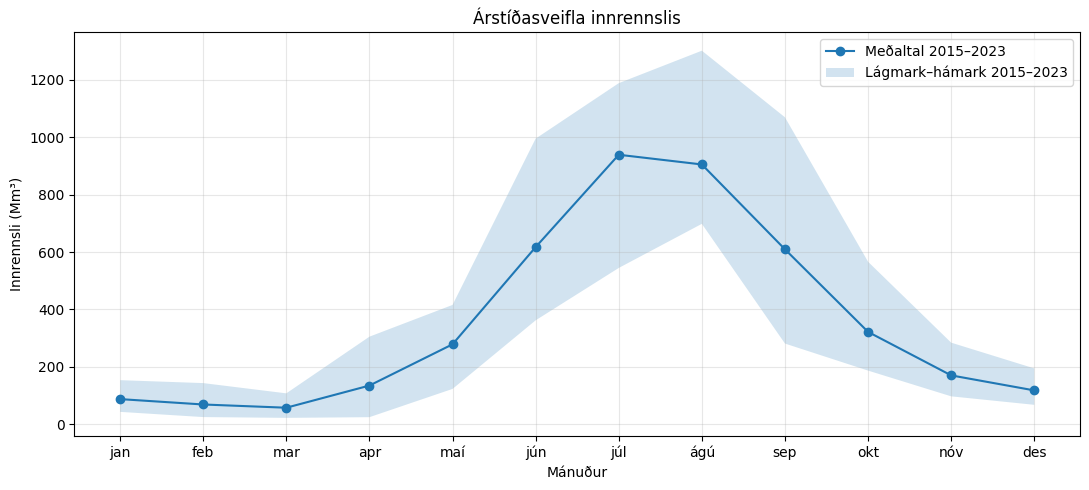

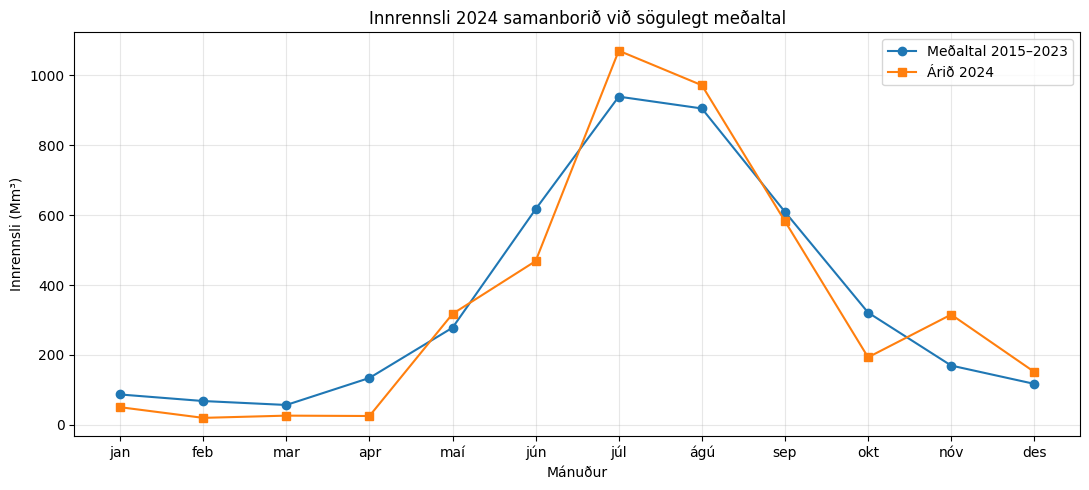

Minnsta meðalinnrennsli: mar
Mesta meðalinnrennsli: júl
Meðalinnrennsli á ári: 4303 Mm³
Innrennsli 2024: 4194 Mm³


In [ ]:
# @title
# Meðaltal, lágmark og hámark fyrir hvern mánuð
medaltal = I_thj.mean(axis=0)
lagmark = I_thj.min(axis=0)
hamark = I_thj.max(axis=0)

manudir = np.arange(1, 13)

# Mynd 1: Árstíðasveifla innrennslis
plt.figure(figsize=(11, 5))

plt.plot(manudir, medaltal, marker="o", label="Meðaltal 2015–2023")
plt.fill_between(
    manudir, lagmark, hamark,
    alpha=0.2, label="Lágmark–hámark 2015–2023"
)

plt.xticks(manudir, MAN)
plt.xlabel("Mánuður")
plt.ylabel("Innrennsli (Mm³)")
plt.title("Árstíðasveifla innrennslis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Mynd 2: Prófunarárið 2024
plt.figure(figsize=(11, 5))

plt.plot(manudir, medaltal, marker="o", label="Meðaltal 2015–2023")
plt.plot(manudir, I_2024, marker="s", label="Árið 2024")

plt.xticks(manudir, MAN)
plt.xlabel("Mánuður")
plt.ylabel("Innrennsli (Mm³)")
plt.title("Innrennsli 2024 samanborið við sögulegt meðaltal")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Samantekt
print("Minnsta meðalinnrennsli:", MAN[np.argmin(medaltal)])
print("Mesta meðalinnrennsli:", MAN[np.argmax(medaltal)])
print(f"Meðalinnrennsli á ári: {I_thj.sum(axis=1).mean():.0f} Mm³")
print(f"Innrennsli 2024: {I_2024.sum():.0f} Mm³")


Þetta sýnir mjög greinilega árstíðarsveiflurnar sem eru hér á landi. Þetta gefur því ákveðna vísbendingu um að það eru möguleikar á að besta þetta og að það skili mælanlegum mun. Þetta er auðvitað bara innrennsli en ekki magn í lóninu.

Þótt heildarinnrennsli ársins 2024 hafi verið nálægt sögulegu meðaltali var dreifing þess milli mánaða töluvert frábrugðin. Þetta sýnir að heildarinnrennsli ársins nægir ekki eitt og sér til að skipuleggja raforkuafhendingu, heldur skiptir tímasetning innrennslis einnig verulegu máli.

## 3.6 Samfella innrennslis milli mánaða

Við skoðum hvort frávik frá venjulegu innrennsli í einum mánuði tengist frávikum í næsta mánuði. Þetta hjálpar okkur að meta hvort upplýsingar um innrennsli síðasta mánaðar geti nýst við ákvörðun um afhendingu raforku.


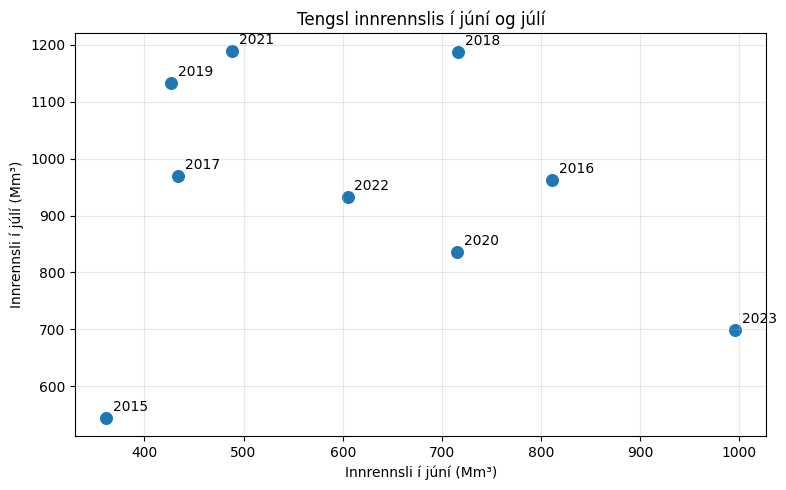

Fylgni júní og júlí: -0.124
Fylgni frávika milli samliggjandi mánaða: 0.145
Fjöldi mánaðapara: 107


In [ ]:
# @title
# Berum saman júní og júlí fyrir hvert þjálfunarár
juni = I_thj[6]
juli = I_thj[7]

fylgni = juni.corr(juli)

plt.figure(figsize=(8, 5))
plt.scatter(juni, juli, s=70)

# Merkjum hvert ár við sinn punkt
for ar in I_thj.index:
    plt.annotate(
        str(ar),
        (juni.loc[ar], juli.loc[ar]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Innrennsli í júní (Mm³)")
plt.ylabel("Innrennsli í júlí (Mm³)")
plt.title("Tengsl innrennslis í júní og júlí")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Fylgni júní og júlí: {fylgni:.3f}")

# Fjarlægjum árstíðasveifluna áður en við
# skoðum tengsl milli samliggjandi mánaða.
fravik = I_thj - I_thj.mean(axis=0)

fyrri = []
naesti = []

# Jan-feb, feb-mar, ..., nóv-des
for man in range(1, 12):
    fyrri.extend(fravik[man].to_numpy())
    naesti.extend(fravik[man + 1].to_numpy())

# Desember yfir í janúar næsta árs
for ar in range(2015, 2023):
    fyrri.append(fravik.loc[ar, 12])
    naesti.append(fravik.loc[ar + 1, 1])

fylgni_fravika = np.corrcoef(fyrri, naesti)[0, 1]

print(f"Fylgni frávika milli samliggjandi mánaða: {fylgni_fravika:.3f}")
print(f"Fjöldi mánaðapara: {len(fyrri)}")


Fylgni milli innrennslis í júní og júli er veik og fylgni frávika milli samliggjandi mánaða er líka veik, sem bendir til þess að innrennsli eins mánaðar gefi mjög takmarkaðar upplýsingar um innrennsli næsta mánaðar.

Þetta þýðir samt ekki að innrennsli hvers mánaðar er óháð.

## 3.7 Vatnsjafnvægi við fasta raforkuafhendingu

Við skoðum hvernig vatnsstaðan þróast yfir árið ef alltaf er reynt að afhenda 537 MW. Byrjunarstaða er 1.600 Mm³ og innrennsli er mánaðarlegt meðaltal áranna 2015–2023.

Þessi keyrsla er einföld viðmiðun, ekki bestunarlausn. Ef vatn er ekki nægilegt er afhending takmörkuð við það sem er mögulegt og forgangsorka hefur forgang.

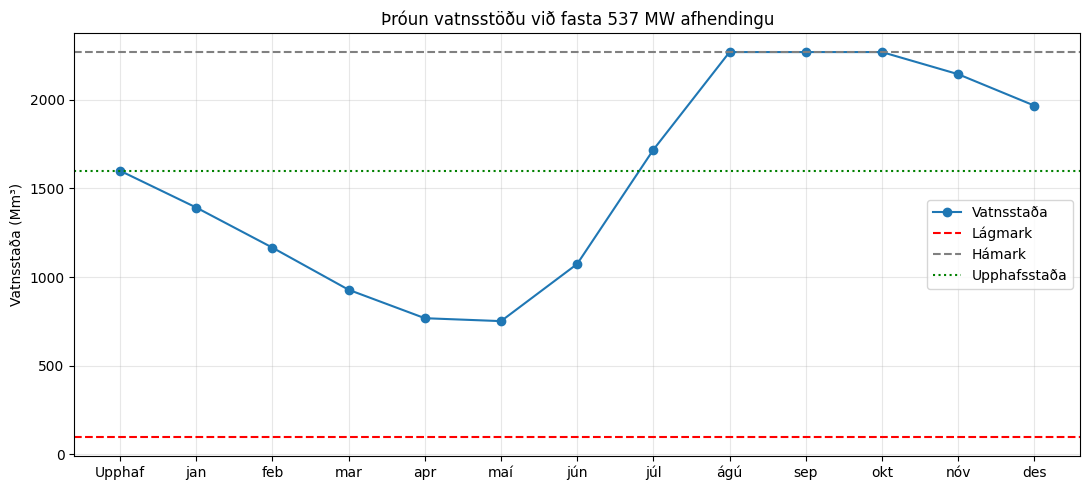

Lokastaða lóns: 1967.8 Mm³
Heildaryfirfall: 401.4 Mm³
Meðalafhending viðbótarorku: 54.0 MW
Fjöldi mánaða með skort á forgangsorku: 0


In [ ]:
# @title

# 7. Vatnsjafnvægi við fasta afhendingu

V_min = 100
V_max = 2270
V = 1600

P_forgangur = 483
P_vidbot = 54
P_samtals = P_forgangur + P_vidbot

k = 690 / 144
C = 2.628

stodur = [V]
afhending = []
yfirfall = []
skortur = []

for man in range(1, 13):
    I = I_thj[man].mean()

    # Vatn sem má nýta án þess að fara undir lágmarkið
    tiltakt = max(0, V + I - V_min)

    # Vatnsþörf fyrir fulla afhendingu
    q_oskad = P_samtals / k
    vatn_oskad = C * q_oskad

    # Takmörkum afhendingu við tiltækt vatn
    vatn_notad = min(vatn_oskad, tiltakt)
    P_raun = (vatn_notad / C) * k

    # Forgangsorka hefur forgang
    forgangur_afhent = min(P_forgangur, P_raun)
    vidbot_afhent = max(0, P_raun - forgangur_afhent)

    # Reiknum stöðuna og yfirfall
    V_nytt = V + I - vatn_notad
    spill = max(0, V_nytt - V_max)
    V = min(V_nytt, V_max)

    stodur.append(V)
    afhending.append(vidbot_afhent)
    yfirfall.append(spill)
    skortur.append(P_forgangur - forgangur_afhent)

plt.figure(figsize=(11, 5))
plt.plot(range(13), stodur, marker="o", label="Vatnsstaða")
plt.axhline(V_min, linestyle="--", color="red", label="Lágmark")
plt.axhline(V_max, linestyle="--", color="gray", label="Hámark")
plt.axhline(1600, linestyle=":", color="green", label="Upphafsstaða")

plt.xticks(range(13), ["Upphaf"] + list(MAN))
plt.ylabel("Vatnsstaða (Mm³)")
plt.title("Þróun vatnsstöðu við fasta 537 MW afhendingu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Lokastaða lóns: {V:.1f} Mm³")
print(f"Heildaryfirfall: {sum(yfirfall):.1f} Mm³")
print(f"Meðalafhending viðbótarorku: {np.mean(afhending):.1f} MW")
print(f"Fjöldi mánaða með skort á forgangsorku: {sum(s > 0 for s in skortur)}")


Við meðalinnrennsli áranna 2015–2023 er hægt að afhenda full 537 MW allt árið án þess að skerða forgangsorku. Vatnsstaðan lækkar yfir veturinn og vorið en hækkar aftur þegar innrennsli eykst yfir sumarið. Í útreikningunum myndast einnig um 401 Mm³ af yfirfalli vegna takmarkaðs geymslurýmis.

Niðurstaðan byggir hins vegar á föstu meðalinnrennsli og tekur ekki tillit til óvissu eða óvenjulega þurrra tímabila. Hún staðfestir því ekki að hægt sé að uppfylla kröfuna um 95% árlegan afhendingaráreiðanleika.

###Samantekt og tenging við kvika bestun

Greiningin sýnir að ákvarðanir um raforkuafhendingu ráðast bæði af árstíðabundnu innrennsli og tiltækri vatnsstöðu. Þótt full afhending sé möguleg við meðalinnrennsli skapa sveiflur milli mánaða og ára óvissu um framtíðarframboð vatns.

Til að taka tillit til þessarar óvissu verður innrennsli næst skipt í flokka og reiknuð mánaðarbundin líkindafylki út frá sögulegum gögnum. Þau verða síðan nýtt í kviku bestunarlíkani til að ákvarða hvenær hagkvæmast sé að afhenda eða skerða viðbótarorkuna, með það að markmiði að hámarka vænta afhendingu og tryggja tilskilinn áreiðanleika forgangsorkunnar.

# 3.8 Flokkun innrennslis og líkindafylki

In [ ]:
%run -i "/content/drive/MyDrive/When_to_Curtail/hluti_2.py"

<Figure size 640x480 with 0 Axes>

## 3.8.1 Flokkun mánaðarlegs innrennslis

Innrennsli hvers mánaðar er skipt í þrjá flokka: lítið, miðlungs og mikið innrennsli. Flokkamörkin eru reiknuð sérstaklega fyrir hvern mánuð út frá 33% og 67% hundraðshlutamörkum þjálfunargagnanna frá 2015-2023.

Þannig er tekið tillit til árstíðasveiflna og tryggt að flokkunin miðist við innrennsli sem er dæmigert fyrir hvern mánuð. Árið 2024 er ekki notað við ákvörðun flokkamarkanna.

In [ ]:
mork, flokkar = hluti_2_1()

=== 2.1 Flokkun innrennslis 2015–2023 ===
            1         2         3         4         5         6         7         8         9         10        11        12
ar                                                                                                                          
2015  Miðlungs  Miðlungs     Mikið     Lítið     Lítið     Lítið     Lítið  Miðlungs     Mikið     Mikið  Miðlungs  Miðlungs
2016  Miðlungs     Lítið     Lítið     Lítið     Lítið     Mikið  Miðlungs     Mikið  Miðlungs     Mikið     Mikið     Mikið
2017     Mikið     Mikið  Miðlungs  Miðlungs     Mikið     Lítið  Miðlungs     Lítið     Mikið     Mikið     Lítið     Lítið
2018     Mikið     Mikið  Miðlungs  Miðlungs  Miðlungs     Mikið     Mikið     Lítið     Lítið     Lítið     Mikið     Mikið
2019     Mikið  Miðlungs  Miðlungs     Mikið  Miðlungs     Lítið     Mikið     Lítið     Lítið  Miðlungs     Lítið  Miðlungs
2020     Lítið  Miðlungs     Lítið     Lítið  Miðlungs  Miðlungs     Lítið     Miki

##3.8.2 Mat á mánaðarbundnum líkindafylkjum

Fyrir hvern mánuð er myndað 3 $\times$ 3 fylki sem sýnir líkur á næsta innrennslisflokki miðað við flokk fyrri mánaðar.

Við útreikningana eru aðeins notuð umskipti innan þjálfunartímabilsins 2015-2023. Fyrir janúar er notað innrennsli desember árið á undan, þar sem gögn frá desember 2014 eru ekki tiltæk er fyrsta janúarumskiptið frá desember 2015 til janúar 2016.

In [ ]:
talningar, P_emp = hluti_2_2(flokkar)


=== 2.2 Dæmi: júní -> júlí ===
Talningar:
          Lítið  Miðlungs  Mikið
Lítið         1         1      1
Miðlungs      1         1      1
Mikið         1         1      1

Líkindafylki fyrir júlí:
          Lítið  Miðlungs  Mikið
Lítið     0.333     0.333  0.333
Miðlungs  0.333     0.333  0.333
Mikið     0.333     0.333  0.333


## 3.8.3 Meðhöndlun flokka án sögulegra umskipta

Þar sem þjálfunargögnin ná aðeins yfir níu ár getur skort sögulegar athuganir fyrir ákveðin umskipti. Ef engin athugun er til í röð líkindafylkis eru í staðinn notaðar líkur úr normaldreifingu sem er löguð að innrennsli þess mánaðar sem verið er að spá fyrir um.

In [ ]:
P_man, stadgenglar = hluti_2_3(talningar, P_emp, mork)


=== 2.3 Meðhöndlun tómra raða ===
Líkindafylki tilbúin: 12
Engar tómar raðir fundust.


## 3.8.4 Sannprófun líkindafylkja

Skoðum svo hvort allar líkur lendu ekki örugglega á bilinu 0 til 1 og að summan sé 1.


=== 2.4 Sannprófun ===
Öll 12 líkindafylkin standast sannprófun.


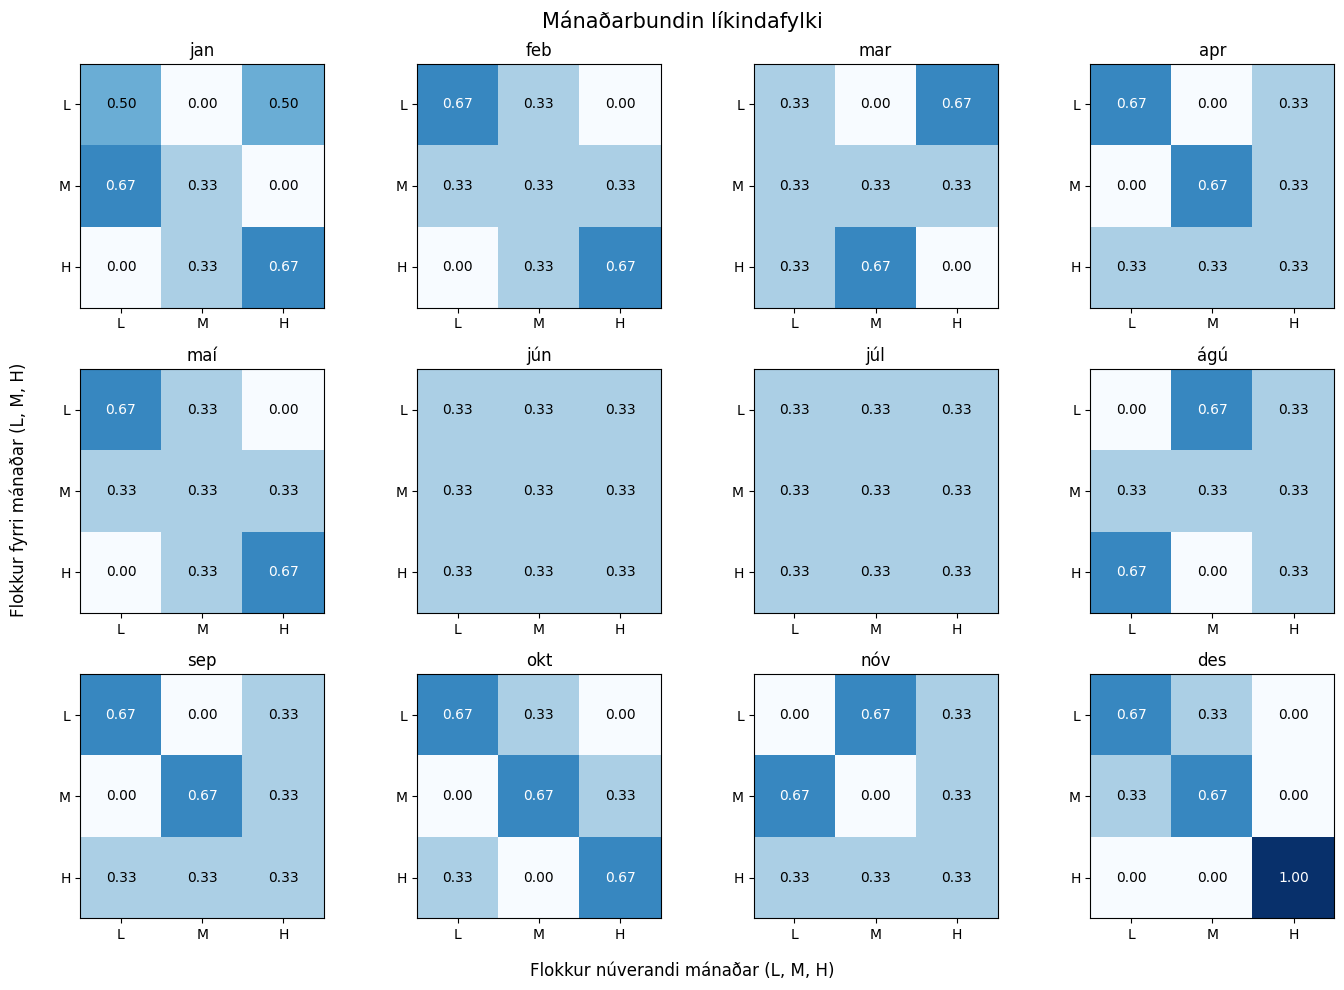


Meðalinnrennsli hvers flokks (Mm³):
     Lítið  Miðlungs   Mikið
jan   50.5      87.9   122.2
feb   31.8      58.4   114.3
mar   33.4      59.8    77.3
apr   47.6      95.7   259.1
maí  144.2     296.3   393.7
jún  407.6     602.9   841.0
júl  692.9     955.0  1169.9
ágú  730.0     858.4  1127.8
sep  367.3     569.0   892.0
okt  193.5     257.9   512.5
nóv  110.4     151.7   246.9
des   73.5      97.8   180.4

Desemberflokkur fyrir prófun 2024: Lítið


In [ ]:
I_flokkar, upphafsflokkur_2024 = hluti_2_4(mork, flokkar, talningar, P_man)

# 4. Stærðfræðileg uppsetning SDP-líkans

Markmið verkefnisins er að ákveða hversu mikið af 54 MW viðbótarorkunni eigi að afhenda í hverjum mánuði til að hámarka væntar tekjur, en líka að tryggja að 483 MW forgangsorkan sé afhent með að minnsta kosti 95% áreiðanleika yfir árið.

Til að leysa verkefnið er notað Markov-ákvörðunarferli (MDP), þar sem ákvarðanir eru teknar mánaðarlega yfir 12 mánaða tímabil með hliðsjón af vatnsstöðu lónsins og óvissu um framtíðarinnrennsli.

## 4.1 Stikar og forsendur

Við skilgreinum tímabilin:

$$
t\in\{1,2,\ldots,12\}
$$

Fastar líkansins eru:

$$
\begin{aligned}
V_{\min}&=100 &&\text{Mm}^3\\
V_{\max}&=2270 &&\text{Mm}^3\\
P_F&=483 &&\text{MW}\\
P_C&=54 &&\text{MW}\\
P_{\max}&=575 &&\text{MW}\\
q_{\max}&=144 &&\text{m}^3/\text{s}\\
k&=\frac{690}{144}
&&\text{MW}/(\text{m}^3/\text{s})\\
c&=2.628
&&\text{Mm}^3/(\text{m}^3/\text{s})
\end{aligned}
$$

Innrennsli er táknað með $I_t$ og mælt í Mm³.

Í tölvulíkaninu er innrennsli hvers flokks
nálgað með meðalinnrennsli úr hluta 2.

## 4.2 Ástand kerfisins (State)

Ástand kerfisins í mánuði $t$ er skilgreint sem:

$$
\boxed{s_t=(V_t,C_t,f_t)}
$$

þar sem:

- $V_t$ er vatnsstaða í upphafi mánaðar, mæld í Mm³.
- $C_t\in\{0,1,2\}$ er innrennslisflokkur mánaðarins, þ.e. lítið, miðlungs eða mikið innrennsli.
- $f_t\in\{0,1\}$ segir til um hvort skortur á forgangsorku hafi orðið fyrr á árinu.

Í upphafi árs er $f_1=0$. Ef skortur verður í einhverjum mánuði tekur breytan gildið 1 og heldur því út árið.

Ákvörðun er tekin eftir að innrennsli núverandi mánaðar hefur verið metið. Í bestuninni er innrennsli

## 4.3 Löglegar ákvarðanir (Actions)

Ákvörðunarbreytan $a_t$ táknar afhendingu viðbótarorku í MW:

$$
0\leq a_t\leq54
$$

Forgangsorkan, 483 MW, hefur alltaf forgang. Viðbótarorka er aðeins afhent ef nægilegt vatn og framleiðslugeta eru til staðar.

Tiltækt vatn til framleiðslu er:

$$
B_t=\max(0,V_t+I_t-V_{\min})
$$

Hámarksafl miðað við vatnsframboð og tæknilegar takmarkanir er:

$$
\overline P_t=
\min\left(
P_{\max},
kq_{\max},
\frac{kB_t}{c}
\right)
$$

Afhent forgangsorka er:

$$
F_t=\min(483,\overline P_t)
$$

Skortur á forgangsorku er:

$$
D_t=483-F_t
$$

Mengi löglegra ákvarðana verður því:

$$
\boxed{
A_t(s_t)=
\left[
0,
\min\left(
54,\max(0,\overline P_t-F_t)
\right)
\right]
}
$$

Þessi skilgreining tryggir að viðbótarafhending fari ekki yfir 54 MW, að forgangsorkan hafi forgang og að vatnsstaða lónsins fari ekki undir leyfilegt lágmark.

## 4.4 Ástandsbreyting (Transition)

Heildarframleiðsla í mánuði $t$ er:

$$
P_t=F_t+a_t
$$

Rennsli um hverfla er:

$$
q_t=\frac{F_t+a_t}{k}
$$

Vatnsjafnvægi lónsins er:

$$
V_{t+1}=V_t+I_t-cq_t-Sp_t
$$

þar sem yfirfall er skilgreint sem:

$$
Sp_t=
\max\left(
0,V_t+I_t-cq_t-V_{\max}
\right)
$$

Við fáum því:

$$
\boxed{
V_{t+1}=
\min\left(
V_{\max},
V_t+I_t-\frac{c(F_t+a_t)}{k}
\right)
}
$$

Löglegar ákvarðanir tryggja jafnframt:

$$
V_{\min}\leq V_{t+1}\leq V_{\max}
$$

Staða skortsbreytunnar uppfærist samkvæmt:

$$
\boxed{
f_{t+1}=\max(f_t,\mathbb{1}_{\{D_t>0\}})
}
$$

þar sem $\mathbb{1}_{\{D_t>0\}}$ er 1 ef skortur verður á forgangsorku í mánuðinum, en annars 0.

## 4.5 Umskiptalíkur (Probability)

Líkur á innrennslisflokki næsta mánaðar eru reiknaðar út frá sögulegum gögnum áranna 2015–2023.

Fyrir innrennslisflokka $i$ og $j$ eru umskiptalíkurnar:

$$
\boxed{
P_{t+1}(i,j)=
\Pr(C_{t+1}=j\mid C_t=i)
}
$$

Líkindafylkin eru þau sömu og reiknuð voru í hluta 2.

Fyrir tiltekið ástand og ákvörðun fæst vatnsstaða næsta mánaðar úr vatnsjafnvæginu. Óvissan um næsta ástand felst því í innrennslisflokki næsta mánaðar.

Umskiptalíkur SDP-líkansins eru:

$$
\Pr(s_{t+1}=(V',j,f')\mid s_t,a_t)
=
\begin{cases}
P_{t+1}(C_t,j), &
\text{ef }V'=V_{t+1}\text{ og }f'=f_{t+1},\\
0, & \text{annars}.
\end{cases}
$$

Við upphaf árs er flokkur desembermánaðar fyrra árs dreginn úr sögulegri dreifingu desemberflokka. Líkindafylki janúar er síðan notað til að ákvarða innrennslisflokk fyrsta mánaðarins.

## 4.6 Ávinningur (Reward)

Markmiðið er að hámarka vænta afhendingu viðbótarorku yfir árið. Grunnávinningur hvers mánaðar er því:

$$
R_t(s_t,a_t)=a_t
$$

Til að taka einnig tillit til forgangsorku er bætt við refsingu fyrir skort:

$$
\boxed{
R_t(s_t,a_t)=a_t-\mu D_t
}
$$

þar sem $\mu=10$ er vægi skortsrefsinga í útfærslu líkansins.

Afhent viðbótarorka yfir árið er:

$$
E_{\mathrm{viðbót}}=
730\sum_{t=1}^{12}a_t
$$

mælt í MWh.

Þar sem verð viðbótarorkunnar er talið fast er hámarkun væntrar afhendingar jafngild hámarkun væntra viðbótartekna.

Yfirfall er ekki refsað sérstaklega í ávinningsfallinu heldur reiknað og metið í niðurstöðugreiningunni.


## 4.7 Markfall, áreiðanleiki og lokamarkmið

Upphaflegt markmið verkefnisins er:

$$
\max_{\pi}
\mathbb{E}_{\pi}
\left[
\sum_{t=1}^{12}a_t
\right]
$$

með árlegu áreiðanleikaskilyrði:

$$
\boxed{
\Pr_{\pi}(D_t=0\;\forall t=1,\ldots,12)\geq0.95
}
$$

Skilyrðið nær til alls ársins, ekki til hvers mánaðar fyrir sig.

Líkanið tekur einnig mið af því að æskilegt er að vatnsstaðan í lok árs sé að minnsta kosti jafnhá upphafsstöðunni:

$$
V_{13}\geq V_1
$$

Í tölvulíkaninu er lokamarkmiðið meðhöndlað með refsingu fyrir þann vatnsforða sem vantar upp á upphafsstöðuna.

Lokagildi líkansins er:

$$
\boxed{
J_{13}(V_{13},f_{13})
=
-M\max(0,V_1-V_{13})-\lambda f_{13}
}
$$

þar sem:

- $M$ er refsing fyrir hvern Mm³ sem vantar upp á lokamarkmiðið.
- $\lambda$ er refsing fyrir ár þar sem skortur verður á forgangsorku.
- $f_{13}=1$ ef skortur hefur orðið einhvern tíma á árinu.

Grunngildi lokarefsingar er valið sem:

$$
M=2\frac{k}{c}
\approx3.65
$$

mælt í MW-mánuðum á hvern Mm³.

Besta stefnan er fyrst fundin með $\lambda=0$. Ef árlegur áreiðanleiki er undir 95% er $\lambda$ hækkað og líkanið leyst aftur þar til stefna sem uppfyllir áreiðanleikakröfuna finnst, eða niðurstaðan sýnir að engin slík stefna er tiltæk.

Lokavatnsstaðan er þannig mjúkt markmið, en ekki hörð skorða. Það er því mögulegt að líkanið endi undir upphafsstöðu á sumum innrennslisferlum.

## 4.8 Bellman-jafna

SDP-líkanið er leyst með bakvirkri bestun frá desember til janúar.

Fyrir ástandið $s_t=(V_t,C_t,f_t)$ verður Bellman-jafnan:

$$
\boxed{
J_t(s_t)=
\max_{a_t\in A_t(s_t)}
\left\{
a_t-\mu D_t+
\sum_{j=0}^{2}
P_{t+1}(C_t,j)
J_{t+1}(V_{t+1},j,f_{t+1})
\right\}
}
$$

fyrir $t=1,\ldots,11$.

Í desember er ekki lengur tekið væntigildi yfir næsta innrennslisflokk. Þá er notað lokagildið:

$$
\boxed{
J_{12}(s_{12})=
\max_{a_{12}\in A_{12}(s_{12})}
\left\{
a_{12}-\mu D_{12}
+J_{13}(V_{13},f_{13})
\right\}
}
$$

Reikniritið finnur þá ákvörðun sem gefur hæstan samanlagðan ávinning af núverandi afhendingu og væntum framtíðarávinningi.

Vatnsstaðan er staksett í 1 Mm³ skrefum og ákvarðanir um viðbótarafhendingu í 0,5 MW skrefum. Línuleg brúun er notuð þegar framtíðarvatnsstaða lendir á milli punkta ástandsnetisins.

Að lokinni bestun er áreiðanleiki stefnunnar reiknaður með því að fara yfir mögulega innrennslisferla samkvæmt líkindafylkjunum. Þannig er sannprófað hvort fundin stefna uppfylli 95% kröfuna samkvæmt forsendum líkansins.

In [ ]:
# @title
import sys
import importlib

sys.path.insert(0, "/content/drive/MyDrive/When_to_Curtail")

import curtail_sdp as cs
importlib.reload(cs)

il = cs.innrennslislikan_ur_hluta2(
    mork, flokkar, talningar, P_man, I_flokkar
)

print("SDP-líkanið er tengt við hluta 2.")
print("Líkindafylki:", il.P.shape)
print("Meðalinnrennsli:", il.Ibar.shape)

SDP-líkanið er tengt við hluta 2.
Líkindafylki: (12, 3, 3)
Meðalinnrennsli: (12, 3)



# 5. Lausn SDP-líkansins

Í þessum hluta er Bellman-jafnan leyst með bakvirkri bestun. Reikniritið notar líkindafylkin og meðalinnrennsli úr hluta 2 til að ákvarða bestu afhendingu viðbótarorku fyrir hverja vatnsstöðu og innrennslisflokk.

Fyrst er reikniritið prófað með upphafsvatnsstöðu 1.600 Mm³. Að því loknu er líkanið leyst fyrir allar þrjár upphafsstöðurnar.


In [ ]:
st = cs.Stillingar(V1=1600)
sdp = cs.SDP(il, st).leysa()

print("Bellman-reikniritið hefur lokið keyrslu.")
print("Fjöldi mánaða:", sdp.stefna.shape[0])
print("Lögun stefnufylkis:", sdp.stefna.shape)
print("Vænt markgildi:", round(sdp.U1(1600), 2))

Bellman-reikniritið hefur lokið keyrslu.
Fjöldi mánaða: 12
Lögun stefnufylkis: (12, 3, 2, 2171)
Vænt markgildi: 638.43


##5.1 Sannprófun grunnstefnunnar

In [ ]:
import numpy as np
mat_grunn = cs.meta_slodir(
    sdp.stefnufall(),
    il,
    V1=1600
)

for lykill, gildi in mat_grunn.items():
    if np.isscalar(gildi) and isinstance(gildi, (int, float, np.number)):
        print(f"{lykill}: {gildi:.4f}")
    else:
        print(f"{lykill}: {gildi}")

p: [2.40854582e-04 1.20427291e-04 1.80640937e-04 ... 2.00712152e-05
 4.01424304e-05 6.02136455e-05]
V13: [1431.63511904 1455.98250521 1615.87833206 ... 1906.1129209  1930.46030706
 2108.26890797]
sum_x: [486. 486. 594. ... 648. 648. 648.]
sum_D: [0. 0. 0. ... 0. 0. 0.]
sum_S: [   0.            0.            0.         ... 1877.02473783 1877.02473783
 1877.02473783]
f: [0 0 0 ... 0 0 0]
Vmin: [434.95137223 434.95137223 434.95137223 ... 977.27327447 977.27327447
 977.27327447]
halli: [168.36488096 144.01749479   0.         ...   0.           0.
   0.        ]
E_afhent_GWh: 469.0996
E_skert_GWh: 3.9404
areidanleiki: 1.0000
E_skortur_GWh: 0.0000
E_yfirfall: 475.0300
E_V13: 1896.9723
P_V13_ge_V1: 0.9849
E_halli: 1.1440
fjoldi_ferla: 66528.0000
man: {'Ex': array([54.        , 54.        , 54.        , 54.        , 54.        ,
       54.        , 54.        , 53.75595692, 53.24959779, 52.47164502,
       52.57017618, 52.55487439]), 'Pskert': array([0.        , 0.        , 0.        , 0.     


## 5.2 Áreiðanleikaskilyrði

Til að kanna hvort 95% áreiðanleikaskilyrðið takmarki afhendingu viðbótarorkunnar er notuð Lagrange-refsing fyrir ár þar sem skortur verður á forgangsorku.

Byrjað er án refsingar. Ef grunnstefnan uppfyllir skilyrðið er ekki þörf á frekari breytingum. Annars er refsingin hækkuð þar til stefna sem uppfyllir áreiðanleikakröfuna finnst.


In [ ]:
lam, sdp_lok, mat_lok, stada = cs.finna_lam(
    il,
    cs.Stillingar(V1=1600),
    krafa=0.95
)

print("Staða skilyrðis:", stada)
print("Lagrange-stiki:", lam)
print(f"Áreiðanleiki: {mat_lok['areidanleiki']:.2%}")
print(f"Afhent viðbótarorka: {mat_lok['E_afhent_GWh']:.2f} GWh")
print(f"Skert viðbótarorka: {mat_lok['E_skert_GWh']:.2f} GWh")

Staða skilyrðis: obindandi
Lagrange-stiki: 0.0
Áreiðanleiki: 100.00%
Afhent viðbótarorka: 469.10 GWh
Skert viðbótarorka: 3.94 GWh



## 5.3 SDP-lausn fyrir mismunandi upphafsvatnsstöður

SDP-líkanið er leyst fyrir þrjár upphafsvatnsstöður, 1.600, 1.800 og 1.950 Mm³. Fyrir hverja stöðu er fundin afhendingarstefna og metið hvort hún uppfylli 95% árlegt áreiðanleikaskilyrði.

Niðurstöðurnar eru síðan notaðar til að bera saman afhendingu viðbótarorku, skerðingu og þróun vatnsstöðu yfir árið.


In [ ]:
grunnur = {}

for V1 in cs.V1_GILDI:

    if V1 == 1600:
        lam_V1 = lam
        sdp_V1 = sdp_lok
        stada_V1 = stada
    else:
        lam_V1, sdp_V1, _, stada_V1 = cs.finna_lam(
            il,
            cs.Stillingar(V1=V1),
            krafa=0.95
        )

    rs = cs.meta_slodir(
        sdp_V1.stefnufall(),
        il,
        V1=V1,
        geyma=True
    )

    grunnur[V1] = {
        "st": sdp_V1.st,
        "sdp": sdp_V1,
        "rs": rs,
        "lam": lam_V1,
        "stada": stada_V1
    }

    print(
        f"V1 = {V1} Mm³ | "
        f"Áreiðanleiki: {rs['areidanleiki']:.2%} | "
        f"Afhent: {rs['E_afhent_GWh']:.2f} GWh | "
        f"Skert: {rs['E_skert_GWh']:.2f} GWh | "
        f"Skilyrði: {stada_V1}"
    )

V1 = 1600 Mm³ | Áreiðanleiki: 100.00% | Afhent: 469.10 GWh | Skert: 3.94 GWh | Skilyrði: obindandi
V1 = 1800 Mm³ | Áreiðanleiki: 100.00% | Afhent: 469.10 GWh | Skert: 3.94 GWh | Skilyrði: obindandi
V1 = 1950 Mm³ | Áreiðanleiki: 100.00% | Afhent: 398.30 GWh | Skert: 74.74 GWh | Skilyrði: obindandi



## 5.4 Myndræn framsetning SDP-stefnunnar

Bestu afhendingarstefnurnar eru sýndar með stefnukortum sem lýsa því hvernig ákvörðun um afhendingu viðbótarorku breytist eftir vatnsstöðu, mánuði og innrennslisflokki.

Einnig er sýnd þróun vatnsstöðu yfir árið og vænt skerðing fyrir mismunandi upphafsvatnsstöður.


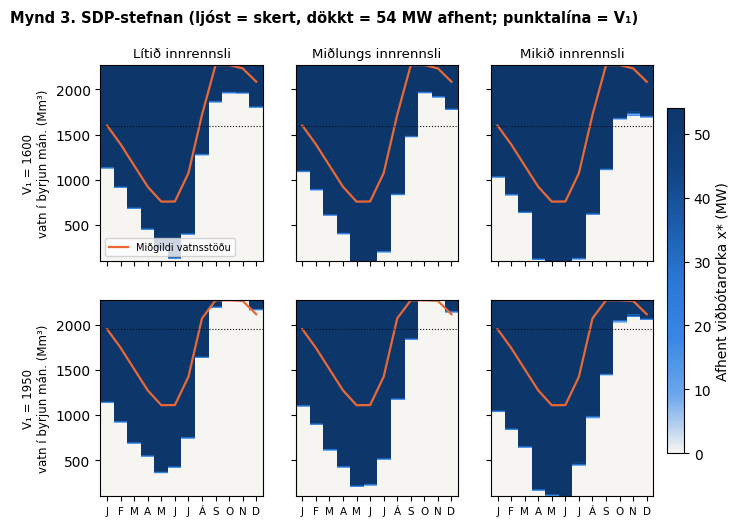

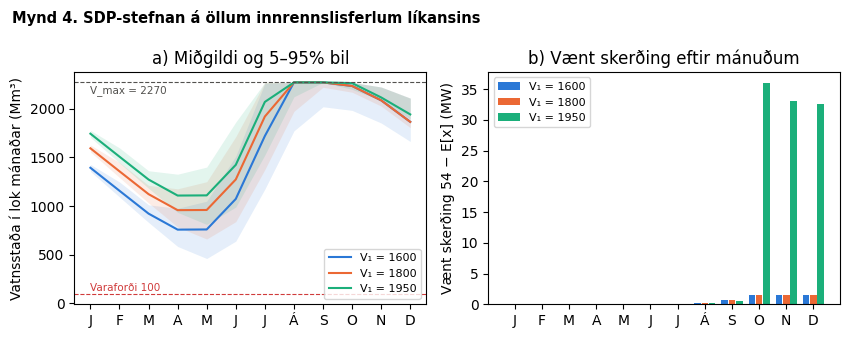

In [ ]:
import importlib
importlib.reload(cs)

cs.teikna_stefnukort(grunnur)
cs.teikna_ferla_og_skerdingu(grunnur);


## 5.5 Samanburður afhendingarstefna

Til að meta árangur SDP-líkansins er besta afhendingarstefnan borin saman við tvær einfaldari leiðir. Annars vegar er gert ráð fyrir að viðbótarorka sé alltaf afhent þegar nægilegt vatn er til staðar og hins vegar er notuð stefna sem byggir á væntu innrennsli í stað þess að taka sérstaklega tillit til óvissu.

Stefnurnar eru metnar út frá afhentri viðbótarorku, skerðingu, áreiðanleika, yfirfalli og lokavatnsstöðu lónsins.


In [ ]:
import importlib
importlib.reload(cs)

samanburdur, likindatafla, skerding_tafla, snid = cs.samanburdur_stefna(
    grunnur, il
)

display(samanburdur)

,stefna,V1,tekjur_%,afhent_GWh,skert_GWh,áreiðanleiki,skortur_GWh,yfirfall_Mm3,E_V13,P(V13≥V1),E_halli_Mm3,markgildi
0,Alltaf afhenda,1600,100.0,473.0,-0.0,1.0,0.0,475.0,1894.0,0.966,3.7,634.4
1,Aldrei afhenda,1600,0.0,0.0,473.0,1.0,0.0,727.0,1997.0,1.000,0.0,0.0
2,Vissujafngildi,1600,99.3,469.7,3.3,1.0,0.0,475.0,1897.0,0.977,1.5,638.2
3,SDP,1600,99.2,469.1,3.9,1.0,0.0,475.0,1897.0,0.985,1.1,638.4
4,Fullkomin vitneskja,1600,99.0,468.1,5.0,1.0,0.0,475.0,1898.0,1.000,0.0,641.2
5,Alltaf afhenda,1800,100.0,473.0,-0.0,1.0,0.0,654.0,1915.0,0.966,3.7,634.4
6,Aldrei afhenda,1800,0.0,0.0,473.0,1.0,0.0,924.0,2001.0,1.000,0.0,0.0
7,Vissujafngildi,1800,99.3,469.7,3.3,1.0,0.0,654.0,1917.0,0.977,1.5,638.2
8,SDP,1800,99.2,469.1,3.9,1.0,0.0,654.0,1918.0,0.985,1.1,638.4
9,Fullkomin vitneskja,1800,99.0,468.1,5.0,1.0,0.0,654.0,1919.0,1.000,0.0,641.2


In [ ]:
display(likindatafla)

,1600,1800,1950
P_aldrei_skert,0.954,0.954,0.111
P_skert_jan_jul,0.000,0.000,0.000
P_skert_agu_des,0.046,0.046,0.889
P_fullt_sep,0.820,0.933,0.979
P_yfirfall,0.842,0.941,0.982


In [ ]:
display(skerding_tafla)

,jan,feb,mar,apr,maí,jún,júl,ágú,sep,okt,nóv,des
Vænt skerðing (MW),,,,,,,,,,,,
1600,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.75,1.53,1.43,1.45
1800,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.75,1.53,1.43,1.45
1950,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.51,36.00,33.01,32.61



### Túlkun samanburðar

Samanburðurinn sýnir að SDP-stefnan skilar ekki alltaf mestri afhendingu viðbótarorku, en nær hærra markgildi en einfaldari stefnurnar. Ástæðan er sú að líkanið tekur bæði mið af afhendingu og því að varðveita nægilega mikið vatn í lok ársins.

Fyrir upphafsvatnsstöðuna 1.600 Mm³ skilar stefnan „Alltaf afhenda“ 473,0 GWh en SDP-stefnan 469,1 GWh. Markgildi SDP er hins vegar 638,4 samanborið við 634,4 fyrir stefnuna „Alltaf afhenda“. Munurinn endurspeglar áhrif lokavatnsstöðurefsingarinnar í markfallinu.

Áhrif lokamarkmiðsins eru sérstaklega mikil þegar upphafsvatnsstaðan er 1.950 Mm³. Þá skilar SDP-stefnan 398,3 GWh af viðbótarorku og líkur á að ná upphaflegri vatnsstöðu í lok árs eru aðeins 44,4%. Þetta sýnir að lokamarkmiðið er erfitt að uppfylla við þessa upphafsstöðu, jafnvel þótt viðbótarafhending sé takmörkuð.

Allar stefnurnar í samanburðinum uppfylla 95% árlega áreiðanleikakröfuna samkvæmt líkaninu fyrir þessar þrjár upphafsstöður. Áreiðanleikaskilyrðið er því óbindandi í þessum tilvikum. Samanburðurinn sýnir fremur áhrif þess að varðveita vatn í lóninu en áhrif áreiðanleikaskilyrðisins sjálfs.

Stefnan með fullkominni vitneskju er notuð sem viðmið til að meta virði upplýsinga um framtíðarinnrennsli. Hún er ekki framkvæmanleg sem raunveruleg rekstrarstefna þar sem innrennsli framtíðarmánaða er óþekkt þegar ákvarðanir eru teknar.



## 5.6 Söguleg ár og prófunarárið 2024

Til að skoða hvernig SDP-stefnan hefði virkað við mismunandi innrennsli er hún prófuð á sögulegum gögnum áranna 2015–2023 og sérstaklega á árinu 2024, sem var ekki notað við gerð líkansins.

Fyrir hvert ár og hverja upphafsvatnsstöðu er reiknuð afhent viðbótarorka, skerðing, lokavatnsstaða og yfirfall. Einnig er sýnt í hvaða mánuðum viðbótarorkan hefði verið afhent að fullu eða skert.


In [ ]:
import importlib
importlib.reload(cs)

I_sdp = t["innrennsli_Mm3"].unstack("man")

soguleg, tafla_ara = cs.soguleg_ar_tafla(
    grunnur, il, I_sdp
)

display(tafla_ara)

print("█ = 54 MW afhent")
print("▒ = skert að hluta")
print("· = skert að fullu")

skert_GWh                    manudir                                 V13  \
V1        1600  1800   1950          1600          1800          1950    1600   
ar                                                                              
2015      39.4  39.4   24.5  ███████·████  ███████·████  ███████▒████  1997.8   
2016       0.0   0.0    0.0  ████████████  ████████████  ████████████  2086.3   
2017       0.0   0.0   78.8  ████████████  ████████████  ██████████··  1889.3   
2018       0.0   0.0   57.7  ████████████  ████████████  ████████▒·██  1989.2   
2019       0.0   0.0   78.8  ████████████  ████████████  ██████████··  1875.0   
2020       0.0   0.0  118.3  ████████████  ████████████  █████████···  1802.2   
2021       0.0  32.1  118.3  ████████████  ███████████▒  █████████···  1775.9   
2022       0.0   0.0   39.4  ████████████  ████████████  █████████·██  2091.0   
2023       0.0  57.3  118.3  ████████████  ██████████▒·  █████████···  1753.9   
2024       0.0   0.0   39.4  ████████████  ████████████  █████████·██  2046.7   

                     yfirfall                 
V1      1800    1950     1600   1800    1950  
ar                                            
2015  1997.8  1997.8     54.0  254.0   392.8  
2016  2086.3  2086.3    596.6  796.6   946.6  
2017  1889.3  1948.5    776.7  976.7  1126.7  
2018  1989.2  2032.6    294.6  494.6   644.6  
2019  1875.0  1934.2    283.4  483.4   633.4  
2020  1802.2  1891.0    128.5  328.5   478.5  
2021  1800.1  1864.8    771.0  971.0  1121.0  
2022  2091.0  2120.6    413.5  613.5   763.5  
2023  1797.0  1842.8    773.6  973.6  1123.6  
2024  2046.7  2076.3    212.8  412.8   562.8

█ = 54 MW afhent
▒ = skert að hluta
· = skert að fullu


## 	5.7 Næmnigreining lokamarkmiðs

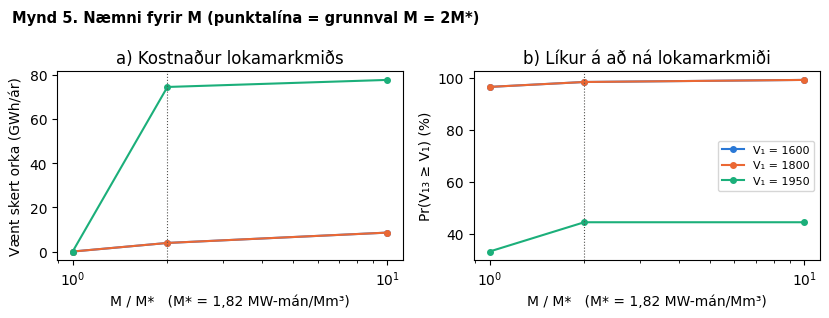

skert_GWh            P_V13_ge_V1                \
V1                     1600 1800  1950        1600   1800   1950   
M_sinnum_Mstjarna                                                  
1.0                    -0.0 -0.0  -0.0       0.966  0.966  0.331   
2.0                     3.9  3.9  74.7       0.985  0.985  0.444   
10.0                    8.6  8.6  77.9       0.993  0.993  0.444   

                  skert_jan_jul_MWman            
V1                               1600 1800 1950  
M_sinnum_Mstjarna                                
1.0                               0.0  0.0  0.0  
2.0                               0.0  0.0  0.0  
10.0                              4.7  4.7  3.0

In [ ]:
naemni_M, naemni_tafla = cs.naemni_lokamarkmids(
    il,
    margfeldi=(1, 2, 10)
)

display(naemni_tafla)


## 5.8 Prófun SDP-stefnunnar á árinu 2024

Til að kanna hvernig SDP-stefnan virkar utan þjálfunargagnanna er hún prófuð á raunverulegu innrennsli ársins 2024. Árið var ekki notað við mat á líkindafylkjum eða ákvörðun innrennslisflokka.

Við prófunina er fylgst með afhendingu viðbótarorku, vatnsstöðu lónsins, yfirfalli og mögulegum skorti á forgangsorku. Niðurstöðurnar eru síðan bornar saman við mælda framleiðslu virkjunarinnar.


,man,I,flokkur,V_byrjun,x,F,D,yfirfall,V_lok
0,jan,50.5,Lítið,1600.0,54.0,483.0,0.0,0.0,1355.9
1,feb,20.0,Lítið,1355.9,54.0,483.0,0.0,0.0,1081.4
2,mar,26.3,Lítið,1081.4,54.0,483.0,0.0,0.0,813.2
3,apr,25.3,Lítið,813.2,54.0,483.0,0.0,0.0,544.0
4,maí,317.5,Miðlungs,544.0,54.0,483.0,0.0,0.0,567.0
5,jún,468.6,Lítið,567.0,54.0,483.0,0.0,0.0,741.1
6,júl,1070.7,Mikið,741.1,54.0,483.0,0.0,0.0,1517.3
7,ágú,971.8,Mikið,1517.3,54.0,483.0,0.0,0.0,2194.6
8,sep,582.7,Miðlungs,2194.6,54.0,483.0,0.0,212.8,2270.0
9,okt,193.3,Lítið,2270.0,54.0,483.0,0.0,0.0,2168.8


,M = 2M*,M = 10M*,M = 100M*
afhent_GWh,473.0,473.0,419.4
skert_GWh,0.0,0.0,53.7
skertir_man,0.0,0.0,2.0
skortur_GWh,0.0,0.0,0.0
skortsmanudir,0.0,0.0,0.0
yfirfall,212.8,212.8,253.1
V13,2046.7,2046.7,2046.7
Vmin,544.0,544.0,584.3
halli,0.0,0.0,0.0


,areidanleiki,E_afhent_GWh,E_skert_GWh,P_V13_ge_V1
M/M*,,,,
2,1.0,468.976444,4.063556,0.984781
10,1.0,464.146238,8.893762,0.993192
100,1.0,449.986594,23.053406,0.997629


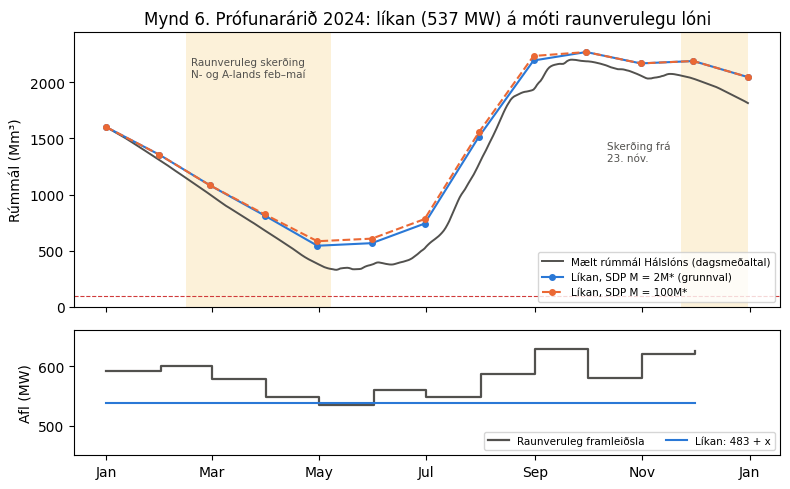

In [ ]:
prof2024, tafla2024, exante2024 = cs.profun_2024(
    il, I_sdp, grunnur
)

display(prof2024[2].round(1))
display(tafla2024)
display(exante2024)

cs.teikna_profun_2024(prof2024, klst);


## 5.9 Klukkustundaprófun

SDP-líkanið byggir á mánaðarlegum ákvörðunum og gerir ráð fyrir 730 klukkustundum í hverjum mánuði. Til að meta takmarkanir þeirrar nálgunar er afhendingarstefnan fyrir árið 2024 skoðuð með hliðsjón af klukkustundagögnum.

Markmiðið er að kanna hvort mánaðarleg niðurstaða gefi raunhæfa mynd af afhendingargetu virkjunarinnar þegar tekið er tillit til sveiflna innan mánaðar.


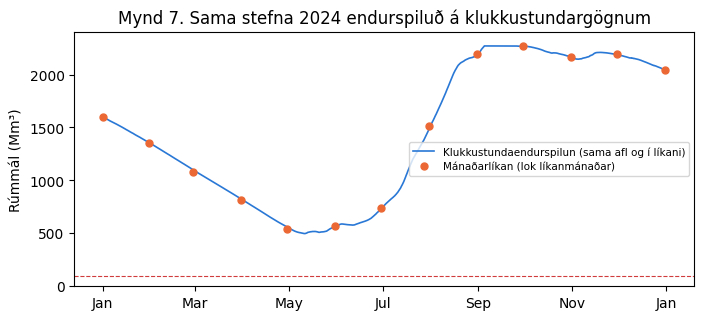

,klst í mán,"líkan, lok mán","klst, lok mán","klst, lægst í mán",dýfa undir lok mán
jan,744,1356.0,1350.0,1350.0,0.0
feb,696,1081.0,1089.0,1089.0,0.0
mar,744,813.0,816.0,816.0,0.0
apr,720,544.0,550.0,550.0,0.0
maí,744,567.0,568.0,497.0,53.0
jún,720,741.0,746.0,568.0,0.0
júl,744,1517.0,1516.0,747.0,0.0
ágú,744,2195.0,2188.0,1518.0,0.0
sep,720,2270.0,2267.0,2189.0,0.0
okt,744,2169.0,2160.0,2160.0,0.0


In [ ]:
klst_tafla, k24 = cs.klukkustundaprof_2024(
    prof2024, klst
)

display(klst_tafla)


## 5.10 Óvissa í líkindafylkjum

Líkindafylki SDP-líkansins eru metin út frá níu árum af sögulegum innrennslisgögnum og því er nokkur óvissa í mati þeirra. Til að kanna áhrif þessarar óvissu eru búin til ný líkindafylki með slembiúrtökum úr Dirichlet-dreifingu.

Fyrir hvert úrtak er annars vegar metin afhending með upphaflegri SDP-stefnu og hins vegar með stefnu sem er endurreiknuð út frá nýju líkindafylkjunum. Þannig er hægt að skoða hversu mikið óvissa í innrennslislíkaninu hefur áhrif á vænta afhendingu og lokavatnsstöðu.


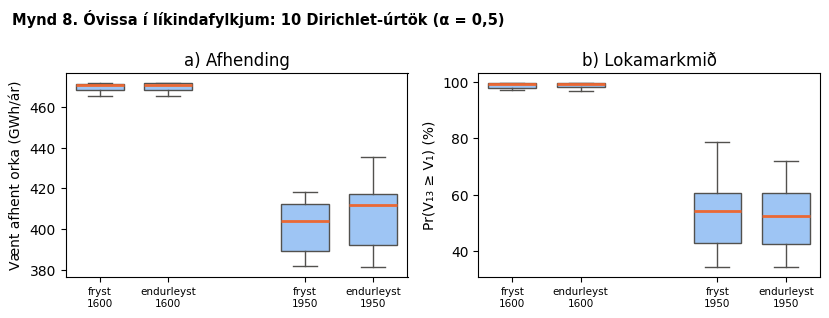


Upphafsvatnsstaða: 1600 Mm³
Fryst stefna: {'E_afhent_GWh': [465.741, 470.788, 471.82], 'P_V13_ge_V1': [0.97, 0.991, 0.996], 'E_halli': [0.236, 0.59, 3.25], 'areidanleiki': [1.0, 1.0, 1.0]}
Endurreiknuð stefna: {'E_afhent_GWh': [465.886, 470.92, 472.048], 'P_V13_ge_V1': [0.97, 0.991, 0.994], 'E_halli': [0.3, 0.689, 3.221], 'areidanleiki': [1.0, 1.0, 1.0]}
Eftirsjá: [0.07, 0.18, 0.49]

Upphafsvatnsstaða: 1950 Mm³
Fryst stefna: {'E_afhent_GWh': [382.514, 403.73, 417.062], 'P_V13_ge_V1': [0.345, 0.542, 0.743], 'E_halli': [7.582, 14.851, 24.641], 'areidanleiki': [1.0, 1.0, 1.0]}
Endurreiknuð stefna: {'E_afhent_GWh': [381.24, 411.859, 430.739], 'P_V13_ge_V1': [0.345, 0.526, 0.692], 'E_halli': [9.817, 17.68, 27.963], 'areidanleiki': [1.0, 1.0, 1.0]}
Eftirsjá: [0.04, 0.94, 5.96]


In [ ]:
ovissa, kassar = cs.ovissa_likindafylkja(
    grunnur,
    il,
    I_thj,
    n_urtok=10
)

for V1 in (1600, 1950):
    print(f"\nUpphafsvatnsstaða: {V1} Mm³")
    print("Fryst stefna:", ovissa[V1]["fryst"])
    print("Endurreiknuð stefna:", ovissa[V1]["endurleyst"])
    print("Eftirsjá:", ovissa[V1]["eftirsja_MWman_5_50_95"])



## 5.11 Álagsprófun áreiðanleika

Til að meta hversu traust SDP-stefnan er er hún prófuð við óhagstæðari innrennslisaðstæður. Markmiðið er að kanna hvort stefnan geti áfram tryggt afhendingu forgangsorku með að minnsta kosti 95% árlegum áreiðanleika þegar forsendur um innrennsli breytast.

Niðurstöðurnar gefa vísbendingu um hversu viðkvæm afhendingarstefnan er fyrir frávikum frá sögulegu innrennslismynstri.


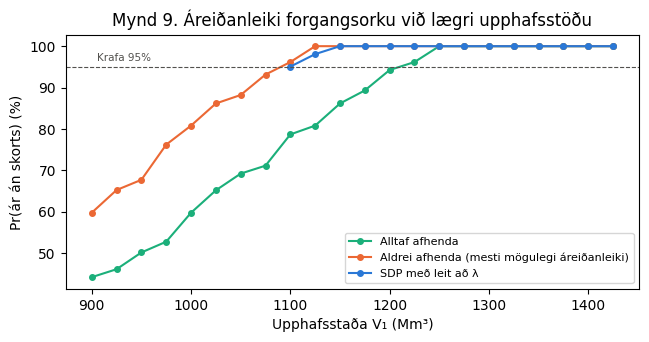

,V1,rel_alltaf,rel_aldrei,stada,lam,rel_SDP,afhent_SDP,skortur_SDP_GWh,afhent_alltaf
0,900,0.4417,0.5974,engin_stefna,NaN,NaN,NaN,NaN,438.5
1,925,0.4609,0.6523,engin_stefna,NaN,NaN,NaN,NaN,440.5
2,950,0.5014,0.6770,engin_stefna,NaN,NaN,NaN,NaN,443.1
3,975,0.5274,0.7620,engin_stefna,NaN,NaN,NaN,NaN,445.7
4,1000,0.5974,0.8080,engin_stefna,NaN,NaN,NaN,NaN,448.7
5,1025,0.6516,0.8615,engin_stefna,NaN,NaN,NaN,NaN,453.4
6,1050,0.6920,0.8820,engin_stefna,NaN,NaN,NaN,NaN,456.0
7,1075,0.7112,0.9314,engin_stefna,NaN,NaN,NaN,NaN,459.4
8,1100,0.7867,0.9616,bindandi,0.688,0.9506,411.1,0.92,462.4
9,1125,0.8080,1.0000,obindandi,0.000,0.9808,426.8,0.00,464.9


In [ ]:
alagsprof = cs.alagsprof_areidanleika(il)

display(alagsprof)


## 5.12 Yfirfallsgreining

Yfirfall verður þegar vatnsstaða lónsins nær hámarki og ekki er hægt að geyma allt innrennslið. Í þessum hluta er mælt yfirfall borið saman við yfirfall samkvæmt SDP-líkaninu.

Samanburðurinn sýnir hvernig líkanið nýtir geymslurými lónsins og hvort breytingar á afhendingarstefnu hafi áhrif á það magn vatns sem fer í yfirfall.


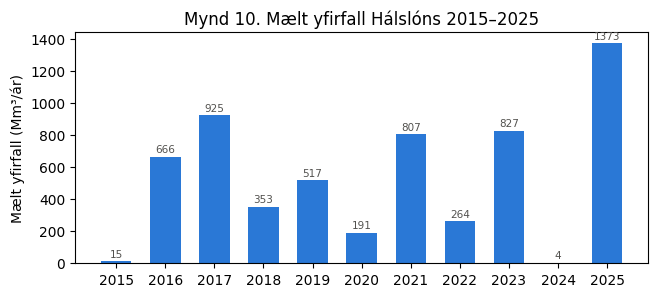

yfirfall_Mm3  afl_medal  klst_i_man  orka_yfirfalls_GWh  \
ar   man                                                            
2015 10           14.5      579.3         744                19.3   
2016 8           152.9      568.7         744               203.5   
     9           251.9      575.1         720               335.2   
     10          259.9      561.0         744               345.9   
     11            1.1      587.8         720                 1.4   
2017 8            95.3      585.9         744               126.8   
     9           466.5      604.4         720               620.9   
     10          362.8      559.1         744               482.9   
2018 8           319.3      555.4         744               425.0   
     9            34.2      567.2         720                45.5   
2019 8           245.1      526.4         744               326.2   
     9           171.4      565.0         720               228.1   
     10          100.7      538.2         744               134.1   
2020 8            82.6      537.2         744               110.0   
     9           108.2      537.1         720               144.0   
2021 8           274.1      564.0         744               364.9   
     9           533.0      557.6         720               709.4   
2022 9           220.2      611.6         720               293.1   
     10           43.3      574.9         744                57.6   
2023 8           566.6      596.4         744               754.1   
     9           259.4      608.1         720               345.3   
2024 9             4.0      628.3         720                 5.3   
2025 8           664.1      561.0         744               883.9   
     9           614.8      559.9         720               818.3   
     10           94.6      563.7         744               125.9   

          laust_afl_690_MW  laust_rennsli_m3s  yfirfall_m3s  
ar   man                                                     
2015 10              110.7               23.1           5.4  
2016 8               121.3               25.3          57.1  
     9               114.9               24.0          97.2  
     10              129.0               26.9          97.0  
     11              102.2               21.3           0.4  
2017 8               104.1               21.7          35.6  
     9                85.6               17.9         180.0  
     10              130.9               27.3         135.5  
2018 8               134.6               28.1         119.2  
     9               122.8               25.6          13.2  
2019 8               163.6               34.1          91.5  
     9               125.0               26.1          66.1  
     10              151.8               31.7          37.6  
2020 8               152.8               31.9          30.9  
     9               152.9               31.9          41.7  
2021 8               126.0               26.3         102.3  
     9               132.4               27.6         205.6  
2022 9                78.4               16.4          85.0  
     10              115.1               24.0          16.2  
2023 8                93.6               19.5         211.5  
     9                81.9               17.1         100.1  
2024 9                61.7               12.9           1.5  
2025 8               129.0               26.9         247.9  
     9               130.1               27.1         237.2  
     10              126.3               26.4          35.3

,1600,1800,1950
E_yfirfall_Mm3,475.0,654.0,799.0
orka_yfirfalls_GWh,632.0,871.0,1063.0
aukasala_575MW_GWh,48.0,60.0,68.0
aukasala_690MW_GWh,181.0,229.0,262.0


In [ ]:
yfirfall_maelt, yfirfall_likan = cs.yfirfallsgreining(
    grunnur,
    t,
    il=il
)

display(yfirfall_maelt.round(1))
display(yfirfall_likan)


## 5.13 Sannprófun SDP-lausnarinnar

Að lokum er SDP-lausnin sannprófuð til að kanna hvort útreikningarnir séu í samræmi við forsendur líkansins. Sérstaklega er athugað hvort vatnsjafnvægi haldist, hvort vatnsstaða sé innan leyfilegra marka og hvort niðurstöður mismunandi matsaðferða séu samhljóða.

Sannprófunin er notuð til að greina hugsanlegar skekkjur í útfærslunni áður en endanlegar niðurstöður eru teknar saman.


In [ ]:
sannprofun = cs.sannprofa_grunnlausn(grunnur, il)

display(sannprofun.round(4))

,Bellman_U1,markgildi_ferlar,jafnvaegi_max_frav,summa_likinda,afhent_net_GWh,afhent_ferlar_GWh,halli_net,halli_ferlar,laegsta_V
V1,,,,,,,,,
1600,638.4285,638.4306,0.0,1.0,469.1021,469.0996,1.1455,1.144,434.9514
1800,638.4285,638.4306,0.0,1.0,469.1021,469.0996,1.1455,1.144,634.9514
1950,483.2671,483.2649,0.0,1.0,398.3015,398.3042,17.0984,17.100,784.9514



# 6. Umræða

## 6.1 Afhendingarstefna og vatnsstaða

Niðurstöður SDP-líkansins sýna að ákvörðun um afhendingu viðbótarorku ræðst ekki eingöngu af því hversu mikið vatn er tiltækt hverju sinni, heldur einnig af væntu innrennsli næstu mánaða og markmiði um að varðveita vatnsforða í lok ársins.

Fyrir upphafsvatnsstöðurnar 1.600 og 1.800 Mm³ er vænt afhending viðbótarorku um 469,1 GWh og vænt skerðing um 3,9 GWh. Þegar upphafsstaðan er hækkuð í 1.950 Mm³ eykst skerðingin hins vegar í 74,7 GWh. Þessi munur skýrist að verulegu leyti af lokamarkmiði líkansins, þar sem hærri upphafsstaða felur jafnframt í sér hærra markmið um vatnsstöðu í árslok.

Samanburður við einfaldari afhendingarstefnur sýnir að SDP-stefnan skilar ekki alltaf mestri afhendingu í GWh. Hún getur þó náð hærra markgildi vegna þess að tekið er tillit til verðmætis vatnsforðans í lok tímabilsins. Niðurstöðurnar eru því háðar því hversu mikið vægi varðveisla vatns fær í markfallinu.

## 6.2 Afhendingaröryggi og áreiðanleiki

Allar þrjár SDP-stefnurnar ná 100% árlegum áreiðanleika samkvæmt líkindalíkaninu. Þær uppfylla því 95% kröfuna miðað við þær forsendur sem notaðar eru við bestunina.

Áreiðanleikaskilyrðið reyndist óbindandi fyrir þessar upphafsstöður. Það þýðir að ekki þurfti að auka refsingu fyrir skort á forgangsorku til að ná tilskildum áreiðanleika. Þetta jafngildir þó ekki því að raunverulegt afhendingaröryggi virkjunarinnar sé 100%.

Líkindafylkin byggja á aðeins níu árum af þjálfunargögnum og innrennsli er nálgað með þremur flokkum fyrir hvern mánuð. Óvissugreiningin og álagsprófanirnar sýna því mikilvægi þess að kanna hvort niðurstöðurnar haldist þegar forsendur líkansins breytast.

## 6.3 Prófunarárið 2024

Árið 2024 var ekki notað við gerð líkindafylkjanna og var því notað sem sjálfstætt prófunarár. Með upphafsvatnsstöðu 1.600 Mm³ skilaði SDP-stefnan fullri afhendingu 54 MW viðbótarorkunnar alla tólf mánuðina, án skorts á forgangsorku.

Lokavatnsstaðan samkvæmt prófuninni var um 2.047 Mm³ og reiknað yfirfall um 213 Mm³. Niðurstaðan sýnir að stefnan hefði samkvæmt einfölduðu vatnsjafnvægi líkansins getað afhent alla viðbótarorkuna á þessu ári.

Þetta er þó ekki fullkomin lýsing á raunverulegum rekstri Fljótsdalsstöðvar. Raunveruleg afhending getur einnig ráðist af takmörkunum flutningskerfisins, rekstrarástandi virkjunarinnar og öðrum þáttum sem ekki eru hluti af líkaninu. Skerðingar sem tilkynntar voru árið 2024 þurfa því ekki að vera í mótsögn við niðurstöðu SDP-prófunarinnar.

## 6.4 Yfirfall og nýting vatnsforða

Yfirfall felur í sér að vatn rennur fram hjá virkjuninni án þess að nýtast til raforkuframleiðslu. Í verkefnisgögnunum kemur fram að yfirfall hafi orðið á níu af ellefu árum, sem bendir til þess að vatnsframboð hafi á ákveðnum tímabilum verið meira en hægt var að geyma eða nýta.

Þótt þetta geti bent til möguleika á aukinni raforkusölu er ekki hægt að gera ráð fyrir að allt yfirfall hefði verið nýtanlegt. Framleiðslugeta virkjunarinnar, hámarksrennsli um hverfla, eftirspurn eftir raforku og tímasetning innrennslis takmarka hversu mikið vatn er hægt að nýta.

Niðurstöður SDP-líkansins sýna einnig að aukin afhending viðbótarorku leiðir ekki endilega til samsvarandi minnkunar á yfirfalli. Ákvörðunin um að nota eða varðveita vatn þarf að taka mið af aðstæðum yfir allt árið.

## 6.5 Takmarkanir líkansins

Líkanið byggir á einföldun þar sem vatnsforði og innrennsli eru sameinuð í eitt jafngilt lón. Þá eru ákvarðanir teknar mánaðarlega og gert ráð fyrir 730 klukkustundum í hverjum mánuði. Slík nálgun hentar til að greina árstíðabundna vatnsstýringu, en nær ekki að lýsa öllum sveiflum í framleiðslu og innrennsli innan mánaðar.

Klukkustundaprófunin undirstrikar að nægilegt vatn yfir heilan mánuð tryggir ekki sjálfkrafa samfellda raforkuafhendingu á hverri klukkustund. Mánaðarlegur áreiðanleiki er því ekki það sama og raunverulegt afhendingaröryggi á klukkustundagrundvelli.

Auk þess byggir mat á framtíðarinnrennsli á takmörkuðum sögulegum gögnum. Niðurstöður líkansins ber því að túlka sem mat á bestu afhendingarstefnu samkvæmt skilgreindum forsendum, fremur en nákvæma spá um raunverulegan rekstur virkjunarinnar.



# 7. Ályktanir og ráðleggingar

## 7.1 Helstu niðurstöður

Markmið verkefnisins var að finna afhendingarstefnu fyrir 54 MW viðbótarorku sem hámarkar væntan ávinning af raforkuafhendingu, samhliða því að viðhalda að minnsta kosti 95% árlegum áreiðanleika 483 MW forgangsorkunnar.

Niðurstöður SDP-líkansins sýna að hægt er að afhenda stærstan hluta viðbótarorkunnar við þær upphafsvatnsstöður sem voru skoðaðar. Fyrir 1.600 og 1.800 Mm³ er vænt afhending um 469 GWh af 473 GWh mögulegri árlegri viðbótarorku. Við 1.950 Mm³ verður skerðingin hins vegar meiri, fyrst og fremst vegna þess að líkanið leggur aukið vægi á að varðveita vatnsforða í lok árs.

Árlegur áreiðanleiki forgangsorkunnar reyndist 100% samkvæmt grunnlíkaninu fyrir allar þrjár upphafsstöðurnar. Áreiðanleikaskilyrðið var því ekki bindandi í þessum tilvikum. Niðurstöðurnar sýna að lokamarkmið vatnsstöðu getur haft meiri áhrif á afhendingarákvarðanir en sjálf áreiðanleikakrafan.

Samanburður við einfaldari afhendingarstefnur sýnir að SDP-líkanið getur nýst til að taka tillit til verðmætis vatnsforða og óvissu um framtíðarinnrennsli. Niðurstöðurnar ráðast þó að hluta af vali á lokarefsingu og þeim forsendum sem notaðar eru við bestunina.

## 7.2 Ráðleggingar til Landsvirkjunar

Niðurstöðurnar benda til þess að skynsamlegt sé að byggja ákvarðanir um afhendingu viðbótarorku á bæði núverandi vatnsstöðu og væntu innrennsli næstu mánaða. SDP-líkan getur verið gagnlegt við slíka ákvarðanatöku þar sem það metur áhrif núverandi afhendingar á möguleika til framtíðar.

Ráðlagt er að nota slíkt líkan sem stuðning við rekstrarákvarðanir, en uppfæra forsendur þess reglulega með nýjum upplýsingum um vatnsstöðu og innrennsli. Sérstaklega þarf að fylgjast með því hvernig breytt innrennslismynstur hefur áhrif á áreiðanleika forgangsorku.

Einnig er mikilvægt að skilgreina skýrt hversu mikils virði vatnsforði í lok árs er talinn vera. Val á þessu vægi hefur veruleg áhrif á niðurstöður líkansins og getur breytt því hvenær hagkvæmt telst að skerða viðbótarorku.

Áður en sambærilegt líkan væri notað við raunverulegan rekstur þyrfti að taka betur tillit til klukkustundasveiflna, takmarkana flutningskerfisins, rekstrarástands virkjunarinnar og óvissu sem ekki kemur fram í sögulegum innrennslisgögnum.

## 7.3 Lokaorð

Verkefnið sýnir hvernig hægt er að nota kvika bestun með óvissu til að greina samspil raforkuafhendingar, vatnsforða og afhendingaröryggis. Helsti ávinningur aðferðarinnar felst í að ákvarðanir eru teknar með hliðsjón af bæði núverandi aðstæðum og mögulegum áhrifum þeirra síðar á árinu.

Niðurstöðurnar gefa gagnlega mynd af því hvenær skerðing viðbótarorku getur verið réttlætanleg, en ber að túlka innan þeirra takmarkana sem felast í einföldun vatnsaflskerfisins og mati á framtíðarinnrennsli.


# Viðaukar



# Viðauki C - Einstaklingsverkefni 3

**Er afhendingarstefna hópsins í raun 95% áreiðanleg?**

**Höfundur:** Aron Wolfram Jörgensson

## C.1 Markmið og aðferð

Markmið einstaklingsverkefnisins er að kanna hvort afhendingarstefna hópsins uppfylli kröfuna um að 483 MW forgangsorka sé afhent án skorts með að minnsta kosti 95% árlegum áreiðanleika.

Fyrst er stefna hópsins fryst og áreiðanleiki hennar metinn með Monte Carlo-hermun. Sú aðferð er frábrugðin nákvæmri upptalningu innrennslisferla sem notuð var við mat hópsins.

Síðan er framkvæmd leave-one-year-out prófun þar sem eitt þjálfunarár er tekið út í einu. Líkindafylkin eru endurmetin, SDP-líkanið leyst aftur og stefnan prófuð á árinu sem var undanskilið.

Að lokum eru áhrif þess að breyta þjálfunartímabilinu metin með samanburði á áreiðanleika og afhendingu viðbótarorku.


In [ ]:
# @title
import importlib.util
import sys
from pathlib import Path

skra = Path("/content/drive/MyDrive/When_to_Curtail/einstaklingsverkefni_3.py")

print("Skrá til staðar:", skra.is_file())

spec = importlib.util.spec_from_file_location(
    "einstaklingsverkefni_3", str(skra)
)

ev3 = importlib.util.module_from_spec(spec)
sys.modules["einstaklingsverkefni_3"] = ev3
spec.loader.exec_module(ev3)

print("Einstaklingsverkefni 3 tilbúið.")
print("Skráin inniheldur:", [
    nafn for nafn in dir(ev3)
    if not nafn.startswith("_")
])

Skrá til staðar: True
Einstaklingsverkefni 3 tilbúið.
Skráin inniheldur: ['annotations', 'breytt_thjalfun', 'cs', 'hermun_areidanleika', 'leave_one_year_out', 'np', 'ohad_mat', 'pd', 'plt', 'replace', 'samantekt_loyo', 'teikna_loyo']



## C.2 Óháð prófun áreiðanleika

Afhendingarstefnan er fryst og prófuð á 3.000 slembnum ársferlum sem eru myndaðir út frá líkindafylkjum hópsins. Fyrir hvert ár er athugað hvort skortur á forgangsorku hafi komið upp í einhverjum mánuði.

Hlutfall ára án skorts er síðan borið saman við áreiðanleikann sem hópurinn reiknaði. Einnig er reiknað 95% öryggisbil fyrir niðurstöðu hermunarinnar.


In [ ]:
hermun = ev3.hermun_areidanleika(
    grunnur,
    il,
    n=3000,
    frae=2026
)

display(hermun.round(3))

,Hermuð ár,Ár án skorts,Ár með skorti,Áreiðanleiki hermunar (%),95% bil neðra (%),95% bil efra (%),Áreiðanleiki hóps (%),Vænt skerðing hermunar (GWh)
V1,,,,,,,,
1600,3000,3000,0,100.0,99.872,100.0,100.0,3.024
1800,3000,3000,0,100.0,99.872,100.0,100.0,3.645
1950,3000,3000,0,100.0,99.872,100.0,100.0,76.085



## C.3 Leave-one-year-out prófun

Til að meta hvernig afhendingarstefnan virkar utan þeirra gagna sem notuð eru við bestun er framkvæmd leave-one-year-out prófun. Eitt ár er tekið úr þjálfunargögnunum í einu og líkindafylkin endurmetin út frá þeim átta árum sem eftir standa.

SDP-líkanið er síðan leyst aftur og nýja stefnan prófuð á raunverulegu innrennsli ársins sem var undanskilið. Þetta er endurtekið fyrir öll árin 2015–2023.

Fyrir hvert prófunarár er skráð hvort skortur hafi orðið á forgangsorku, ásamt afhendingu viðbótarorku og lokavatnsstöðu.


2015: skortsmanudir=0; afhent=426.3 GWh; áreiðanleiki þjálfunar=100.0%
2016: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2017: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2018: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2019: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2020: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2021: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2022: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%
2023: skortsmanudir=0; afhent=473.0 GWh; áreiðanleiki þjálfunar=100.0%


,Þjálfunarár,Staða bestunar,Áreiðanleiki þjálfunar (%),Forgangsskortur í prófun,Skortsmanudir,Afhent (GWh),Skert (GWh),Lokastaða (Mm³),Yfirfall (Mm³),Lagrange λ
Prófunarár,,,,,,,,,,
2015,8,obindandi,100.0,False,0,426.32,46.72,1997.85,59.50,0.0
2016,8,obindandi,100.0,False,0,473.04,0.00,2086.30,596.56,0.0
2017,8,obindandi,100.0,False,0,473.04,0.00,1889.27,776.66,0.0
2018,8,obindandi,100.0,False,0,473.04,0.00,1989.22,294.61,0.0
2019,8,obindandi,100.0,False,0,473.04,0.00,1875.01,283.44,0.0
2020,8,obindandi,100.0,False,0,473.04,0.00,1802.16,128.46,0.0
2021,8,obindandi,100.0,False,0,473.04,0.00,1775.93,771.05,0.0
2022,8,obindandi,100.0,False,0,473.04,0.00,2091.02,413.47,0.0
2023,8,obindandi,100.0,False,0,473.04,0.00,1753.91,773.58,0.0


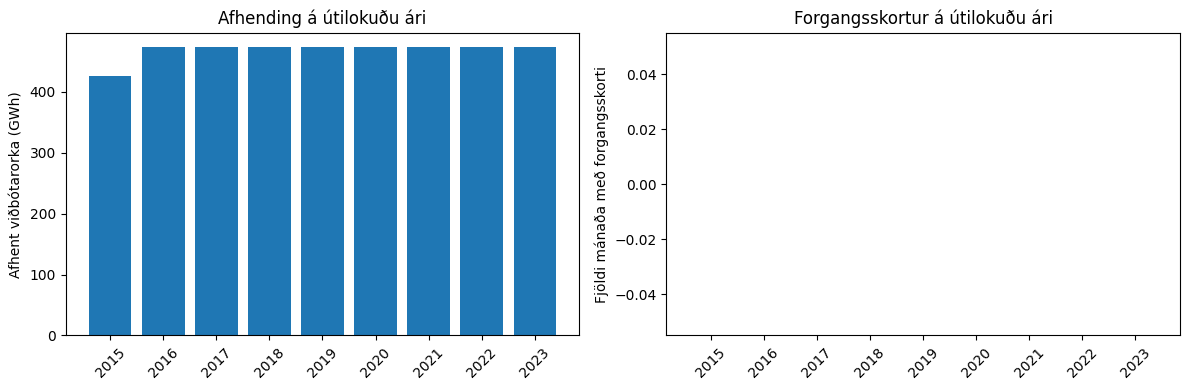

In [ ]:
loyo = ev3.leave_one_year_out(
    I_thj,
    I_sdp,
    V1=1600,
    dV=5,
    dx=2
)

display(loyo.round(2))
ev3.teikna_loyo(loyo);


## C.4 Áhrif breytingar á þjálfunartímabili

Til að kanna hversu háðar niðurstöðurnar eru vali á þjálfunargögnum er líkindalíkanið endurmetið með árunum 2016–2023 í stað 2015–2023.

Fyrst er upprunaleg SDP-stefna hópsins metin með nýju líkindafylkjunum, án þess að afhendingarstefnunni sé breytt. Síðan er SDP-líkanið leyst aftur með breyttum forsendum.

Með þessu er hægt að greina hvort breyting á þjálfunargögnum hafi áhrif á áreiðanleika forgangsorkunnar eða vænta afhendingu viðbótarorku.


In [ ]:
naemni_3, nytt_il = ev3.breytt_thjalfun(
    I_thj,
    grunnur,
    il,
    V1=1600,
    ar_fra=2016
)

display(naemni_3.round(2))

,Áreiðanleiki (%),Afhent (GWh),Fjöldi þjálfunarára
Forsenda,,,
"2015–2023, fryst hópstefna",100.0,469.10,9
"2016–2023, fryst hópstefna",100.0,471.73,8
"2016–2023, endurleyst stefna",100.0,471.87,8



## C.5 Umræða og ályktanir

Niðurstöður sjálfstæðu sannprófunarinnar styðja mat hópsins á afhendingaröryggi forgangsorkunnar. Í Monte Carlo-hermun með 3.000 ársferlum varð enginn skortur á forgangsorku og metinn áreiðanleiki var því 100%. Neðri mörk 95% öryggisbilsins voru 99,87%. Hermunin byggir þó á sömu líkindafylkjum og hóplíkanið og staðfestir því fyrst og fremst samræmi milli reikniaðferðanna.

Leave-one-year-out prófunin gaf sambærilega niðurstöðu. Þegar hvert ár á tímabilinu 2015–2023 var undanskilið við þjálfun og stefnan síðan prófuð á því ári varð enginn forgangsorkuskortur. Afhending viðbótarorku var lægst árið 2015, eða 426,3 GWh, en á hinum átta árunum var hún um 473 GWh. Við endurlausnirnar var notað grófara reikninet en í hópverkefninu til að stytta keyrslutíma.

Breyting á þjálfunartímabilinu úr 2015–2023 í 2016–2023 hafði heldur ekki áhrif á reiknaðan áreiðanleika. Vænt afhending frystu hópstefnunnar jókst úr 469,10 í 471,73 GWh og endurleyst stefna skilaði 471,87 GWh. Niðurstöðurnar sýna því að afhendingin er að einhverju leyti háð vali á þjálfunargögnum, þótt áreiðanleikinn haldist óbreyttur.

### Styðja niðurstöðurnar 95% áreiðanleika?

Samkvæmt líkindalíkaninu uppfyllir stefna hópsins 95% árlega áreiðanleikakröfuna. Bæði nákvæma mat hópsins og Monte Carlo-hermunin gefa 100% áreiðanleika, og enginn skortur kom fram í sögulegu prófununum.

Þetta er þó ekki nægileg sönnun fyrir því að raunverulegt afhendingaröryggi sé að minnsta kosti 95%. Níu söguleg ár eru lítið úrtak þegar verið er að meta atburð sem má samkvæmt kröfunni gerast í allt að 5% ára. Þótt enginn skortur komi fram í níu árum er því ekki hægt að útiloka að raunverulegar líkur á árlegum skorti séu meiri en 5%.

Ekki er heldur rétt að líta á tólf mánuði sama árs sem tólf óháðar prófanir. Vatnsstaða í einum mánuði ræðst af fyrri innrennsli og vatnsnotkun og því geta aðstæður snemma árs haft áhrif á afhendingargetu síðar. Áreiðanleikakrafan miðast jafnframt við að forgangsorkan sé afhent alla tólf mánuðina.

Til að meta raunverulegt afhendingaröryggi með meiri vissu þyrfti lengri gagnaröð, fjölbreyttari þurrkasviðsmyndir og ítarlegra líkan af rekstri virkjunarinnar. Sérstaklega þyrfti að taka tillit til klukkustundasveiflna, rekstrartruflana og takmarkana flutningskerfisins.

### Niðurstaða

Sjálfstæða greiningin bendir til þess að SDP-stefna hópsins sé traust gagnvart þeim breytingum á innrennslisforsendum sem voru prófaðar. Hún stenst 95% áreiðanleikakröfuna samkvæmt líkaninu og enginn forgangsorkuskortur kom fram í sögulegu prófununum.

Niðurstöðurnar styðja því áreiðanleika stefnunnar innan skilgreindra forsendna, en ekki er hægt að yfirfæra þær beint á raunverulegt afhendingaröryggi Fljótsdalsstöðvar.



## C.6 Kóði og endurtekning niðurstaðna

Útreikningar einstaklingsverkefnisins eru útfærðir í `einstaklingsverkefni_3.py` og byggja á sameiginlega SDP-líkaninu í `curtail_sdp.py`.

Til að endurtaka niðurstöðurnar þarf fyrst að keyra gagnavinnslu og SDP-lausn hópverkefnisins. Að því loknu eru eftirfarandi föll keyrð:

- `hermun_areidanleika()` – Monte Carlo-hermun á frystu stefnu hópsins.
- `leave_one_year_out()` – endurmat og prófun fyrir hvert ár 2015–2023.
- `breytt_thjalfun()` – samanburður á þjálfunartímabilunum 2015–2023 og 2016–2023.

Monte Carlo-hermunin notar 3.000 ársferla og slembifræið 2026 til að tryggja endurtakanleika. Í leave-one-year-out prófuninni er notað 5 Mm³ vatnsstöðuskref og 2 MW ákvörðunarskref til að stytta keyrslutímann. Grunnlíkan hópsins notar fínna reikninet.


# Viðauki D - Einstaklingsverkefni 4

**Gildisítrun borin saman við stefnuítrun**

Sófus Máni Bender

## D.1 Markmið og aðferð

Hópurinn leysir SDP-líkanið með bakvirkri bestun. Á endanlegum tímasjóndeildarhring er það gildisítrun (value iteration, VI): í hverjum mánuði, frá desember aftur til janúar, er tekið hámark yfir allar ákvarðanir miðað við þekkt framtíðargildi mánaðarins á eftir.

Markmið einstaklingsverkefnisins er að leysa sama vandamál með stefnuítrun (policy iteration, PI) og bera aðferðirnar saman. Stefnuítrun hefur þrjú skref:

1. **Mat á stefnu.** Fyrir gefna stefnu er gildi hennar reiknað aftur á bak með einni fastri ákvörðun í hverju ástandi, án hámörkunar.
2. **Bæting.** Eitt Bellman-skref er tekið í öllum ástöndum og öllum mánuðum samtímis, miðað við gildi stefnunnar.
3. **Stöðvun.** Skrefin eru endurtekin þar til stefnan breytist ekki lengur.

Prófaðar eru tvær upphafsstefnur: **„alltaf“**, þar sem 54 MW eru afhent þegar vatn leyfir, og **„aldrei“**, þar sem viðbótarorkan er alltaf skert. Einnig eru prófaðar tvær jafnteflisreglur í bætingarskrefinu: regla hópsins, sem velur stærsta x innan 10⁻³ MW-mán frá hámarki, og hefðbundin PI-regla, sem heldur núverandi ákvörðun ef hún er innan sömu marka.

Öllum forsendum hópsins er haldið óbreyttum: ástandið $(V_t, C_t, f_t)$, 1 Mm³ og 0,5 MW reikninet, $M = 2M^*$, $\mu = 10$ og $\lambda$ sem ytri leit hópsins skilaði. Fyrir upphafsstöðurnar 1.600, 1.800 og 1.950 Mm³ var $\lambda^* = 0$, svo sú stilling er fest.

In [ ]:
# @title
import importlib.util
import sys
from pathlib import Path

skra = Path("/content/drive/MyDrive/When_to_Curtail/einstaklingsverkefni_4.py")

print("Skrá til staðar:", skra.is_file())

spec = importlib.util.spec_from_file_location(
    "einstaklingsverkefni_4", str(skra)
)

ev4 = importlib.util.module_from_spec(spec)
sys.modules["einstaklingsverkefni_4"] = ev4
spec.loader.exec_module(ev4)

print("Einstaklingsverkefni 4 tilbúið.")
print("Skráin inniheldur:", [
    nafn for nafn in dir(ev4)
    if not nafn.startswith("_") and callable(getattr(ev4, nafn))
])

## D.2 Sannprófun á mati stefnu

Áður en aðferðirnar eru bornar saman er matsfallið sannprófað. Ef besta stefna hópsins er metin með matsfalli stefnuítrunar á gildið að verða nákvæmlega það sama og gildisítrun hópsins skilar. Stefnuítrun sem byrjar í þeirri stefnu á jafnframt að stöðvast eftir eitt mat.

In [ ]:
sannprofun_4 = ev4.sannprofa_mat(grunnur, il)

display(sannprofun_4)

## D.3 Samanburður gildisítrunar og stefnuítrunar

Stefnuítrun er keyrð fyrir allar þrjár upphafsvatnsstöður, með báðum upphafsstefnum og báðum jafnteflisreglum. Gildisítrun hópsins er keyrð fimm sinnum til að fá stöðugan keyrslutíma.

Afhending, áreiðanleiki og lokavatnsstaða eru metin með nákvæmri upptalningu allra innrennslisferla, eins og hjá hópnum. Dálkarnir „net“ sýna stefnutöfluna sjálfa metna með líkindadreifingu á reikninetinu. Dálkurinn „Ástönd með aðra stefnu“ telur ástönd þar sem stefnuítrun velur aðra ákvörðun en gildisítrun, og „Mesti Q-munur“ sýnir hversu miklu sú ákvörðun munar í gildi.

In [ ]:
samanburdur_4, PI = ev4.bera_saman_VI_PI(grunnur, il)

display(samanburdur_4)
display(ev4.timaskipting(PI))

## D.4 Álagstilvik þar sem áreiðanleikakrafan bindur

Fyrir upphafsstöðurnar þrjár er áreiðanleikinn 100% og $\lambda^* = 0$, svo samanburður á áreiðanleika segir lítið. Í álagsprófun hópsins bindur 95% krafan þegar upphafsstaðan er 1.100 Mm³. Þar er $\lambda^*$ fundið með leit hópsins og síðan fest, og aðferðirnar bornar saman á sama hátt.

In [ ]:
alag_4, PI_alag = ev4.alagstilvik(il, V1=1100)

display(alag_4)

## D.5 Þróun stefnunnar milli ítrana

Taflan sýnir hversu mörg ástönd breytast í bætingarskrefi hverrar ítrunar, eftir mánuðum, ásamt væntu gildi stefnunnar. Fyrri myndin sýnir hlutfall ástanda í hverjum mánuði þar sem stefna ítrunar $k$ víkur frá stefnu gildisítrunar. Seinni myndin sýnir hversu langt gildi stefnunnar er frá besta gildi í hverri ítrun.

In [ ]:
ferill_4 = ev4.ferill_itrana(PI, V1=1600)

display(ferill_4)
ev4.teikna_bylgju(PI, V1=1600);
ev4.teikna_samleitni(PI, grunnur);

## D.6 Jafntefli milli ákvarðana

Til að meta hvort frávik milli aðferðanna séu raunveruleg er athugað hvar besta ákvörðun er ekki einkvæm. Í hverju ástandi lausnar hópsins eru fundin öll x sem eru innan 10⁻³ MW-mán frá besta gildi. Ástönd þar sem ekkert vatn er afgangs fyrir viðbótarorku ($x_{\max} = 0$) eru talin sér, því þar eru allar ákvarðanir eins.

In [ ]:
jafntefli_4, jafntefli_man_4 = ev4.jafnteflagreining(grunnur, il)

display(jafntefli_4)
display(jafntefli_man_4)

## D.7 Umræða og ályktanir

Með jafnteflisreglu hópsins skilar stefnuítrun nákvæmlega sömu stefnu og gildisítrun í öllum 156.312 ástöndum, fyrir báðar upphafsstefnur og allar upphafsstöður. Gildisföllin eru eins og afhending, áreiðanleiki og lokavatnsstaða þau sömu: 469,1 GWh við 1.600 og 1.800 Mm³ og 398,3 GWh við 1.950 Mm³, með 100% áreiðanleika. Sama gildir í álagstilvikinu við 1.100 Mm³, þar sem báðar aðferðir gefa 411,1 GWh og 95,06% áreiðanleika með $\lambda^* = 0{,}6885$.

Stefnuítrun þurfti 5–6 stefnumöt, eða 4–5 stefnubreytingar og eitt staðfestingarmat. Hún tók um 2–2,5 sekúndur á móti um 0,5 sekúndum fyrir gildisítrun. Mat á stefnu er mjög ódýrt, um 0,007 sekúndur, því aðeins ein ákvörðun er reiknuð í hverju ástandi. Hvert bætingarskref kostar hins vegar um 0,4 sekúndur, jafnmikið og heil umferð gildisítrunar, því þar eru allar 110 ákvarðanirnar bornar saman.

Gildi stefnunnar batnar í hverri ítrun. Frá stefnunni „alltaf“ við 1.600 Mm³ fer vænta gildið úr 634,43 í 637,97 MW-mán eftir eina bætingu og í 638,43 eftir tvær. Ein bæting á einföldu reglunni nær því 99,9% af besta gildinu. Seinni ítranirnar laga aðallega ástönd sem hafa litlar líkur.

### Af hverju dugar ein bakvirk umferð?

Á endanlegum tímasjóndeildarhring er gildið í lok ársins þekkt, þ.e. lokarefsingin. Gildi mánaðar $t$ ræðst aðeins af gildi mánaðar $t+1$, ekki af sjálfu sér. Þegar reiknað er frá desember aftur á bak er gildi næsta mánaðar því þegar rétt þegar gildi núverandi mánaðar er reiknað. Hvert stig er reiknað einu sinni og nákvæmlega, og það er enginn fastapunktur sem þarf að nálgast.

Stefnuítrun gerir í raun það sama, en hægar. Bætingin getur aðeins orðið rétt í mánuði $t$ þegar stefnan í mánuðunum á eftir er orðin rétt. Eftir $k$ bætingar er stefnan því örugglega rétt í $k$ síðustu mánuðunum. Myndin í kafla D.5 sýnir þetta: fyrsta bætingin lagar desember strax, og síðasti mánuðurinn með frávik færist aftur á bak í hverri ítrun. Stefnuítrun getur því þurft allt að 13 ítranir og kemst aldrei af með færri bætingarskref en ein umferð gildisítrunar.

### Hvenær er stefnuítrun hentug?

Stefnuítrun er hentugust á óendanlegum tímasjóndeildarhring með afvöxtun, eins og í endurteknu ári. Þá verður gildið að fastapunkti og gildisítrun samleitnir aðeins með hraðanum $\beta$ á hverja ítrun, svo með $\beta = 0{,}99$ þarf hundruð umferða. Stefnuítrun samleitnir þar yfirleitt á fáum ítrunum, því fjöldi stefna er endanlegur.

Hún nýtist einnig þegar mat á stefnu er mun ódýrara en bæting, eins og hér, og þegar góð upphafsstefna er til. Ef áætlunin er leyst aftur í hverjum mánuði gæti stefnuítrun sem byrjar í stefnu síðasta mánaðar samleitnað á einni eða tveimur ítrunum. Jafnframt gefur hver ítrun nothæfa stefnu sem er að minnsta kosti jafngóð og sú fyrri, svo hægt er að stöðva snemma.

Í þessu verkefni er bakvirk bestun hópsins þó bæði einfaldari og hraðari.

### Eru frávikin raunveruleg eða jafntefli?

Með hefðbundnu PI-reglunni endaði stefnuítrun í stefnu sem víkur frá gildisítrun í 450–690 ástöndum af 156.312. Í öllum þeim ástöndum er munur á gildi ákvarðananna innan jafnteflismarka, 10⁻³ MW-mán, og gildisföllin víkja mest um 0,0012 MW-mán. Frávikin eru því jafntefli, ekki raunverulegur munur.

Jafnteflin eru hluti af uppbyggingu líkansins. Ávinningur, vatnsjafnvægi og brúun eru línuleg og lokarefsingin er bútalínuleg, svo gildi ákvörðunar er bútalínulegt í x. Hámarkið getur því legið á láréttum bút, þar sem jafngott er að afhenda 1 MW núna og geyma vatnið til loka ársins. Um 3,9% ástanda hafa ekkert val ($x_{\max} = 0$) og um 0,5–0,6% hafa raunveruleg jafntefli, flest í júní–október og janúar.

Jafntefli eru þó aðeins jafngóð fyrir markfallið með Lagrange-refsingu. Í álagstilvikinu við 1.100 Mm³ hefur stefnutafla hefðbundnu reglunnar 93,6% áreiðanleika og 411,04 GWh afhendingu á reikninetinu, en stefna hópsins 93,2% og 411,09 GWh. Jafnteflisregla hópsins, sem velur stærra x, hallast því kerfisbundið að meiri afhendingu og minni áreiðanleika. Þegar áreiðanleikakrafan bindur er val á jafnteflisreglu því ákvörðun sem ber að skrá, ekki tæknilegt aukaatriði.

Ath.: áreiðanleiki á reikninetinu (93,2%) er lægri en í nákvæmri upptalningu ferla (95,06%), því matið á netinu dreifir líkindamassa línulega milli netpunkta. Báðar aðferðir eru alltaf bornar saman með sama matsfalli.

### Hvað segja niðurstöðurnar um raunverulega kerfið?

Samanburðurinn sýnir að niðurstöður hópsins ráðast ekki af lausnaraðferðinni, því báðar aðferðir leysa sama líkanið eins. Hann segir hins vegar ekkert um hvort líkanið sjálft lýsi Fljótsdalsstöð rétt. Líkanið byggir á þremur innrennslisflokkum sem eru metnir á níu árum, einu sameinuðu lóni og mánaðarlegu vatnsjafnvægi.

Jafnteflin sýna að í sumum ástöndum gerir líkanið ekki upp á milli ákvarðana. Þar ættu önnur sjónarmið að ráða, til dæmis varúð vegna óvissu í líkindafylkjunum eða takmarkanir innan mánaðar sem líkanið nær ekki til.

### Niðurstaða

Stefnuítrun og gildisítrun skila sömu bestu stefnu, sama gildi og sömu afhendingu og áreiðanleika. Gildisítrun er um 4–5 sinnum fljótlegri á þessum endanlega tímasjóndeildarhring, því hún þarf aðeins eina bakvirka umferð. Frávik sem koma fram með annarri jafnteflisreglu eru jafntefli, en þegar áreiðanleikakrafan bindur getur jafnteflisreglan haft lítil áhrif á áreiðanleika og afhendingu.

## D.8 Kóði og endurtekning niðurstaðna

Útreikningar einstaklingsverkefnisins eru útfærðir í `einstaklingsverkefni_4.py` og byggja á sameiginlega SDP-líkaninu í `curtail_sdp.py`, sem er ekki breytt.

Til að endurtaka niðurstöðurnar þarf fyrst að keyra gagnavinnslu og SDP-lausn hópverkefnisins (kaflar 3–5). Að því loknu eru eftirfarandi föll keyrð:

- `sannprofa_mat()` – sannprófun á mati stefnu á móti lausn hópsins.
- `bera_saman_VI_PI()` – stefnuítrun fyrir allar upphafsstöður, tvær upphafsstefnur og tvær jafnteflisreglur.
- `alagstilvik()` – sami samanburður við 1.100 Mm³, þar sem áreiðanleikakrafan bindur.
- `ferill_itrana()`, `teikna_bylgju()` og `teikna_samleitni()` – þróun stefnunnar milli ítrana.
- `jafnteflagreining()` – greining á ástöndum þar sem besta ákvörðun er ekki einkvæm.

Kjarni stefnuítrunarinnar er í föllunum `meta_stefnu()` (mat á stefnu), `baeta()` (bætingarskref) og `stefnuitrun()` (ítrunin sjálf). Notað er sama reikninet og í hópverkefninu, 1 Mm³ og 0,5 MW. Keyrslutímar eru háðir vélbúnaði en hlutfallið milli aðferðanna helst svipað.

##Einstaklingsverkefni 5

Jón Bersi Sigurðsson

In [ ]:
# Uppsetning: finnur gögnin sjálf (vinnumappa, My Drive, deildar Drive-möppur) eða biður um upphal
import os, sys, glob, zipfile

def leita(nafn, rot=".", dypt=3):
    # leitar í vinnumöppunni (ekki inn í Drive) að skrá/möppu sem passar við nafn
    out = []
    for mappa, undir, skrar in os.walk(rot):
        if mappa.count(os.sep) - rot.count(os.sep) >= dypt:
            undir[:] = []
        undir[:] = [u for u in undir if u not in ("drive", "sample_data") and not u.startswith(".")]
        out += [os.path.join(mappa, k) for k in undir + skrar if glob.fnmatch.fnmatch(k, nafn)]
    return out

def finna_mappa():
    for d in leita("original_exports"):
        if os.path.exists(os.path.join(d, "halslon_natturulegt_innrennsli.csv")):
            return d
    return None

MAPPA = os.environ.get("CURTAIL_DATA") or finna_mappa()
if MAPPA is None:
    zipar = leita("hydro_group_project_data*.zip")
    try:
        from google.colab import drive, files
        drive.mount("/content/drive")
        for mynstur in ("/content/drive/MyDrive/hydro_group_project_data*.zip",
                        "/content/drive/MyDrive/When_to_Curtail/hydro_group_project_data*.zip",
                        "/content/drive/.shortcut-targets-by-id/*/**/hydro_group_project_data*.zip",
                        "/content/drive/MyDrive/**/hydro_group_project_data*.zip"):
            zipar += glob.glob(mynstur, recursive=True)
            if zipar:
                break
        if not zipar:
            print("Fann ekki hydro_group_project_data.zip á Drive – veldu skrána í glugganum.")
            zipar = [k for k in files.upload() if k.endswith(".zip")]
    except ImportError:
        pass
    if not zipar:
        raise FileNotFoundError("Fann ekki hydro_group_project_data.zip. Settu hana í vinnumöppuna eða stilltu CURTAIL_DATA.")
    print("Afþjappa:", zipar[0])
    with zipfile.ZipFile(zipar[0]) as z:
        z.extractall(".")
    MAPPA = finna_mappa()
print("Gögn:", MAPPA, sorted(os.listdir(MAPPA)))

Gögn: ./hydro_group_project_data/original_exports ['Yfirlit raða.xlsx', 'expert_note_is.txt', 'fljotsdalsstod_framleidsla.csv', 'fljotsdalsstod_notad_vatn.csv', 'halslon_lonhaed.csv', 'halslon_natturulegt_innrennsli.csv', 'halslon_natturulegt_innrennsli_smoothed.csv', 'halslon_rennsli_um_yfirfall.csv', 'halslon_rummal.csv', 'jokulsargong_rennsli.csv']


In [ ]:
%%writefile curtail_sdp.py
"""
Hvenær á að skerða? Vatnsafl og forgangsorka (Verkefni 4, Aðgerðagreining 2).

Slembið kvikt bestunarlíkan (SDP) fyrir Fljótsdalsstöð:
  * gögn og mánaðarinnrennsli (hluti 1),
  * flokkun innrennslis og líkindafylki (hluti 2),
  * Bellman-lausn aftur á bak (hluti 3–4),
  * mat á stefnum: nákvæm upptalning allra innrennslisferla, dreifing á neti,
    keyrsla á sögulegum árum og klukkustundaendurspilun.

Allar einingar: rúmmál í Mm3 (= GL), afl í MW, rennsli í m3/s, líkanmánuður 730 klst.
"""
from __future__ import annotations

import os
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy import stats

# ----------------------------------------------------------------------------
# 1. Fastar úr verkefnislýsingu
# ----------------------------------------------------------------------------
K = 690 / 144             # MW á hvert m3/s  (P = K q)
Q_MAX = 144.0             # m3/s
P_MAX = 575.0             # MW (ein 115 MW vél í viðhaldi)
KLST = 730                # klst. í líkanmánuði
C = KLST * 3600 / 1e6     # 2,628 Mm3 á hvert m3/s yfir líkanmánuð
V_MIN, V_MAX = 100.0, 2270.0
FAST, AUKA = 483.0, 54.0  # MW forgangsorka og skerðanleg orka
A_VATN = C / K            # Mm3 sem 1 MW notar í einn líkanmánuð (0,5484)
M_JAFN = 1 / A_VATN       # MW-mán á Mm3: vatn í lok árs jafnverðmætt og afhending núna (1,8234)
V1_GILDI = [1600, 1800, 1950]
THJALFUNARAR = list(range(2015, 2024))
PROFUNARAR = 2024
MAN = ["jan", "feb", "mar", "apr", "maí", "jún", "júl", "ágú", "sep", "okt", "nóv", "des"]
FLOKKAR = ["Lítið", "Miðlungs", "Mikið"]
GWH_A_MWMAN = KLST / 1000  # 1 MW í einn líkanmánuð = 0,73 GWh

RADIR = {
    "H": "halslon_natturulegt_innrennsli.csv",       # m3/s, hrátt (EKKI slétta röðin)
    "J": "jokulsargong_rennsli.csv",                 # m3/s
    "yfirfall": "halslon_rennsli_um_yfirfall.csv",   # m3/s
    "notad_vatn": "fljotsdalsstod_notad_vatn.csv",   # m3/s
    "afl": "fljotsdalsstod_framleidsla.csv",         # MW
    "rummal": "halslon_rummal.csv",                  # GL = Mm3
}


# ----------------------------------------------------------------------------
# 2. Gögn (hluti 1)
# ----------------------------------------------------------------------------
def lesa_rod(mappa: str, skra: str) -> pd.DataFrame:
    """Les eina klukkustundarröð: Latin-1, ';', tugakomma, '---' = vantar."""
    d = pd.read_csv(os.path.join(mappa, skra), sep=";", encoding="latin-1", dtype=str)
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    d = d.rename(columns={d.columns[0]: "dags", d.columns[1]: "klst", d.columns[2]: "txt"})
    d = d.dropna(subset=["dags"])
    d["timi"] = pd.to_datetime(d["dags"] + " " + d["klst"], format="%d.%m.%Y %H:%M:%S")
    txt = d["txt"].str.strip().replace({"---": None, "": None})
    d["gildi"] = pd.to_numeric(txt.str.replace(",", ".", regex=False), errors="coerce")
    flogg = [c for c in ("Valid", "Invalid", "Missing", "Quality", "Interpolation") if c in d.columns]
    return d[["timi", "gildi"] + flogg].reset_index(drop=True)


def lesa_gogn(mappa: str) -> dict:
    return {nafn: lesa_rod(mappa, skra) for nafn, skra in RADIR.items()}


def manadartafla(klst: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Mánaðarrúmmál = meðaltal tiltækra klst.-gilda x klst. í almanaksmánuði x 0,0036 (Mm3)."""
    hlutar = []
    for nafn, d in klst.items():
        g = d.groupby([d["timi"].dt.year.rename("ar"), d["timi"].dt.month.rename("man")])["gildi"]
        hlutar.append(pd.DataFrame({f"{nafn}_medal": g.mean(), f"{nafn}_n": g.count()}))
    t = pd.concat(hlutar, axis=1)
    ar_, man_ = t.index.get_level_values("ar"), t.index.get_level_values("man")
    t["klst_i_man"] = pd.to_datetime(pd.DataFrame({"year": ar_, "month": man_, "day": 1})).dt.days_in_month.to_numpy() * 24
    for nafn in ("H", "J", "yfirfall", "notad_vatn"):
        t[f"{nafn}_Mm3"] = t[f"{nafn}_medal"] * t["klst_i_man"] * 0.0036
    t["innrennsli_Mm3"] = t["H_Mm3"] + t["J_Mm3"]
    t["framleidsla_GWh"] = t["afl_medal"] * t["klst_i_man"] / 1000
    t["nothaefur"] = (t["H_n"] >= 0.5 * t["klst_i_man"]) & (t["J_n"] >= 0.5 * t["klst_i_man"])
    t.loc[~t["nothaefur"], "innrennsli_Mm3"] = np.nan
    I = t["innrennsli_Mm3"].unstack("man")
    return t, I


# ----------------------------------------------------------------------------
# 3. Flokkun og líkindafylki (hluti 2)
# ----------------------------------------------------------------------------
def flokka(I_thj: pd.DataFrame) -> tuple[np.ndarray, pd.DataFrame]:
    """Mörk = 1/3 og 2/3 hlutfallsmörk hvers mánaðar (línuleg brúun); flokkur 0/1/2."""
    mork = np.array([np.quantile(I_thj[m].to_numpy(), [1 / 3, 2 / 3]) for m in range(1, 13)])
    flokkar = pd.DataFrame({m: np.searchsorted(mork[m - 1], I_thj[m].to_numpy(), side="right")
                            for m in range(1, 13)}, index=I_thj.index)
    return mork, flokkar


def flokkur(gildi, m: int, mork: np.ndarray):
    """Flokkur nýs gildis í almanaksmánuði m (1–12)."""
    return np.searchsorted(mork[m - 1], gildi, side="right")


def telja_umskipti(flokkar: pd.DataFrame) -> np.ndarray:
    """talningar[t, i, j]: fjöldi ára með flokk i í mánuði t-1 og flokk j í mánuði t (t=0: des árið á undan -> jan)."""
    n = np.zeros((12, 3, 3), dtype=int)
    ar = list(flokkar.index)
    for t in range(1, 12):
        for a in ar:
            n[t, flokkar.loc[a, t], flokkar.loc[a, t + 1]] += 1
    for a in ar:                       # des(a-1) -> jan(a), aðeins innan þjálfunaráranna
        if a - 1 in ar:
            n[0, flokkar.loc[a - 1, 12], flokkar.loc[a, 1]] += 1
    return n


def normal_flokkalikur(I_thj: pd.DataFrame, mork: np.ndarray, m: int) -> np.ndarray:
    """Flokkalíkur normaldreifingar sem er löguð að innrennsli mánaðar m (1–12) í þjálfunarárunum."""
    x = I_thj[m].to_numpy()
    mu, sd = x.mean(), x.std(ddof=1)
    F = stats.norm.cdf(mork[m - 1], mu, sd)
    return np.array([F[0], F[1] - F[0], 1 - F[1]])


def likindafylki(talningar: np.ndarray, I_thj: pd.DataFrame, mork: np.ndarray):
    """P[t, i, j] = Pr(C_t = j | C_{t-1} = i). Tóm röð -> normaldreifingarlíkur mánaðar t."""
    P = np.zeros((12, 3, 3))
    stadgenglar = []
    for t in range(12):
        for i in range(3):
            s = talningar[t, i].sum()
            if s > 0:
                P[t, i] = talningar[t, i] / s
            else:
                P[t, i] = normal_flokkalikur(I_thj, mork, t + 1)
                stadgenglar.append((t, i))
    return P, stadgenglar


def flokkamedaltol(I_thj: pd.DataFrame, flokkar: pd.DataFrame) -> np.ndarray:
    """Ibar[t, c] = meðalinnrennsli flokks c í mánuði t (Mm3)."""
    return np.array([[I_thj.loc[flokkar[t + 1] == c, t + 1].mean() for c in range(3)] for t in range(12)])


def des_dreifing(flokkar: pd.DataFrame) -> np.ndarray:
    """Reynsludreifing desemberflokks á þjálfunarárunum."""
    return np.bincount(flokkar[12].to_numpy(), minlength=3) / len(flokkar)


@dataclass
class Innrennslislikan:
    """Allt sem SDP-líkanið þarf um innrennsli."""
    mork: np.ndarray
    flokkar: pd.DataFrame
    talningar: np.ndarray
    P: np.ndarray
    Ibar: np.ndarray
    pi_des: np.ndarray
    stadgenglar: list = field(default_factory=list)


def smida_innrennslislikan(I_thj: pd.DataFrame) -> Innrennslislikan:
    mork, flokkar = flokka(I_thj)
    n = telja_umskipti(flokkar)
    P, st = likindafylki(n, I_thj, mork)
    return Innrennslislikan(mork, flokkar, n, P, flokkamedaltol(I_thj, flokkar), des_dreifing(flokkar), st)


# ----------------------------------------------------------------------------
# 4. Eðlisfræði eins mánaðar
# ----------------------------------------------------------------------------
def manudur(V, I):
    """Fyrir vatn í byrjun V og innrennsli I: (hámarksafl, afhent forgangsorka F, skortur D, hámark x).
    Forgangsorka fær vatnið fyrst; x <= 54 og x <= það sem eftir er af vatni og afli."""
    W = np.asarray(V, float) + np.asarray(I, float)
    B = np.maximum(0.0, W - V_MIN)
    Pbar = np.minimum(P_MAX, K * np.minimum(Q_MAX, B / C))
    F = np.minimum(FAST, Pbar)
    D = FAST - F
    xmax = np.clip(Pbar - F, 0.0, AUKA)
    return W, F, D, xmax


def lok_manadar(W, F, x):
    """Vatnsjafnvægi: V' = V + I - c q, yfirfall það sem fer yfir V_MAX."""
    Vp = W - C * (F + x) / K
    S = np.maximum(0.0, Vp - V_MAX)
    return np.minimum(Vp, V_MAX), S


# ----------------------------------------------------------------------------
# 5. SDP-líkanið
# ----------------------------------------------------------------------------
@dataclass
class Stillingar:
    V1: float = 1600.0          # upphafsstaða og markmið í lok árs
    M: float = 2 * M_JAFN       # refsing á hvern Mm3 sem vantar upp á V1 í lok árs (MW-mán/Mm3)
    lam: float = 0.0            # Lagrange-refsing fyrir ár með skorti á forgangsorku (MW-mán)
    mu: float = 10.0            # refsing á hvert MW-mán skorts á forgangsorku (forgangur líka milli mánaða)
    dV: float = 1.0             # netbil vatnsstöðu (Mm3)
    dx: float = 0.5             # netbil ákvörðunar (MW)
    jafntefli: float = 1e-3     # ef Q-gildi eru jöfn innan þessara marka (MW-mán) er stærra x valið


class SDP:
    """Bakvirk lausn Bellman-jöfnunnar á ástandinu (V, C, f):
    V = vatnsstaða í byrjun mánaðar, C = innrennslisflokkur mánaðarins (sést áður en ákveðið er),
    f = 1 ef skortur á forgangsorku hefur þegar orðið á árinu."""

    def __init__(self, il: Innrennslislikan, st: Stillingar, Ibar: np.ndarray | None = None):
        self.il, self.st = il, st
        self.Ibar = il.Ibar if Ibar is None else Ibar
        self.Vnet = np.round(np.arange(V_MIN, V_MAX + 1e-9, st.dV), 9)
        self.Xnet = np.round(np.arange(0.0, AUKA + 1e-9, st.dx), 9)
        nV = len(self.Vnet)
        self.J = np.zeros((12, 3, 2, nV))        # gildi eftir að innrennsli mánaðar sést
        self.G = np.zeros((12, 3, 2, nV))        # vænt framtíðargildi eftir ákvörðun (fall af V')
        self.stefna = np.zeros((12, 3, 2, nV))   # x*(t, c, f, V)

    # lokagildi: refsing fyrir að ná ekki V1 og Lagrange-refsing fyrir ár með skorti
    def lokagildi(self, V, f):
        return -self.st.M * np.maximum(0.0, self.st.V1 - V) - self.st.lam * f

    def _framhald(self, t, Vn, c, fn):
        """G_t(V', c, f') með línulegri brúun; c og fn eru fylki eða tölur."""
        out = np.empty_like(Vn)
        c = np.broadcast_to(c, Vn.shape[:1]); fn = np.broadcast_to(fn, Vn.shape[:1])
        for ci in range(3):
            for fi in range(2):
                r = (c == ci) & (fn == fi)
                if r.any():
                    out[r] = np.interp(Vn[r], self.Vnet, self.G[t, ci, fi])
        return out

    def akvarda(self, t, V, I, c, f, hluti=40000):
        """Besta x í mánuði t með einu Bellman-skrefi á raunverulegu ástandi (V, I, c, f).
        Skilar (x, Q-gildi, F, D). Ef jafnt er valið stærra x (afhent frekar en skert)."""
        V = np.atleast_1d(np.asarray(V, float)); I = np.broadcast_to(np.asarray(I, float), V.shape)
        c = np.broadcast_to(np.asarray(c), V.shape); f = np.broadcast_to(np.asarray(f), V.shape)
        if len(V) > hluti:     # skipt í búta til að spara minni
            bitar = [self.akvarda(t, V[i:i + hluti], I[i:i + hluti], c[i:i + hluti], f[i:i + hluti], hluti)
                     for i in range(0, len(V), hluti)]
            return tuple(np.concatenate([b[k] for b in bitar]) for k in range(4))
        W, F, D, xmax = manudur(V, I)
        fn = np.maximum(f, (D > 1e-9).astype(int))
        X = np.concatenate([np.broadcast_to(self.Xnet, (len(V), len(self.Xnet))), xmax[:, None]], axis=1)
        X = np.minimum(X, xmax[:, None])                         # óleyfileg gildi klippt að xmax
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        n, a = X.shape
        cont = self._framhald(t, Vn.reshape(-1), np.repeat(c, a), np.repeat(fn, a)).reshape(n, a)
        Q = X - self.st.mu * D[:, None] + cont
        Qmax = Q.max(axis=1)
        valid = Q >= Qmax[:, None] - self.st.jafntefli
        x = np.where(valid, X, -1.0).max(axis=1)
        Qx = np.where(X == x[:, None], Q, -np.inf).max(axis=1)
        return x, Qx, F, D

    def leysa(self):
        nV = len(self.Vnet)
        for fi in range(2):
            self.G[11, :, fi] = self.lokagildi(self.Vnet, fi)
        for t in range(11, -1, -1):
            for ci in range(3):
                for fi in range(2):
                    x, Q, _, _ = self.akvarda(t, self.Vnet, self.Ibar[t, ci], np.full(nV, ci), np.full(nV, fi))
                    self.stefna[t, ci, fi], self.J[t, ci, fi] = x, Q
            if t > 0:
                # G_{t-1}(V', c_prev, f) = sum_c P_t(c_prev, c) J_t(V', c, f)
                self.G[t - 1] = np.einsum("ij,jfv->ifv", self.il.P[t], self.J[t])
        return self

    def U1(self, V, pi_des=None, f=0):
        """Vænt gildi í byrjun árs áður en janúarinnrennsli sést."""
        pi = self.il.pi_des if pi_des is None else np.asarray(pi_des, float)
        Jjan = np.array([np.interp(V, self.Vnet, self.J[0, c, f]) for c in range(3)])
        return float(pi @ self.il.P[0] @ Jjan)

    def stefnufall(self):
        return lambda t, V, I, c, f: self.akvarda(t, V, I, c, f)[0]


# ----------------------------------------------------------------------------
# 6. Samanburðarstefnur
# ----------------------------------------------------------------------------
def stefna_alltaf(t, V, I, c, f):
    """Afhenda 54 MW alltaf þegar vatn leyfir."""
    return manudur(V, I)[3]


def stefna_aldrei(t, V, I, c, f):
    """Aldrei afhenda skerðanlega orku."""
    return np.zeros_like(np.atleast_1d(np.asarray(V, float)))


class Vissujafngildi:
    """Vissujafngildisstefna (rúllandi áætlun með væntu innrennsli): í hverjum mánuði er leyst
    ákvarðanalaust vandamál þar sem framtíðarinnrennsli = skilyrt vænting miðað við núverandi flokk.
    Sama lokarefsing og sama skortsrefsing og í SDP (refsing lam á hvern skortsmánuð)."""

    def __init__(self, il: Innrennslislikan, st: Stillingar):
        self.il, self.st = il, st
        self.Vnet = np.round(np.arange(V_MIN, V_MAX + 1e-9, st.dV), 9)
        self.Xnet = np.round(np.arange(0.0, AUKA + 1e-9, st.dx), 9)
        self.H = np.zeros((12, 3, len(self.Vnet)))   # H[t, c](V'): gildi frá mánuði t+1 m.v. spá
        for t in range(12):
            for c in range(3):
                self.H[t, c] = self._akvardanalaust(t, c)

    def spa(self, t, c):
        """Vænt innrennsli mánaða t+1..11 miðað við C_t = c."""
        dreif = np.eye(3)[c]
        out = []
        for k in range(t + 1, 12):
            dreif = dreif @ self.il.P[k]
            out.append(float(dreif @ self.il.Ibar[k]))
        return out

    def _skref(self, Vnet, I, Hn):
        W, F, D, xmax = manudur(Vnet, I)
        X = np.minimum(np.concatenate([np.broadcast_to(self.Xnet, (len(Vnet), len(self.Xnet))), xmax[:, None]], 1), xmax[:, None])
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        Q = X - self.st.mu * D[:, None] - self.st.lam * (D[:, None] > 1e-9) + np.interp(Vn, self.Vnet, Hn)
        return Q.max(1)

    def _akvardanalaust(self, t, c):
        Hn = -self.st.M * np.maximum(0.0, self.st.V1 - self.Vnet)
        for I in reversed(self.spa(t, c)):
            Hn = self._skref(self.Vnet, I, Hn)
        return Hn

    def __call__(self, t, V, I, c, f, hluti=40000):
        V = np.atleast_1d(np.asarray(V, float)); I = np.broadcast_to(np.asarray(I, float), V.shape)
        c = np.broadcast_to(np.asarray(c), V.shape)
        if len(V) > hluti:
            return np.concatenate([self(t, V[i:i + hluti], I[i:i + hluti], c[i:i + hluti], None, hluti)
                                   for i in range(0, len(V), hluti)])
        W, F, D, xmax = manudur(V, I)
        X = np.minimum(np.concatenate([np.broadcast_to(self.Xnet, (len(V), len(self.Xnet))), xmax[:, None]], 1), xmax[:, None])
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        cont = np.empty_like(Vn)
        for ci in range(3):
            r = c == ci
            if r.any():
                cont[r] = np.interp(Vn[r], self.Vnet, self.H[t, ci])
        Q = X + cont
        Qmax = Q.max(1)
        return np.where(Q >= Qmax[:, None] - self.st.jafntefli, X, -1.0).max(1)


# ----------------------------------------------------------------------------
# 7. Mat: nákvæm upptalning allra flokkaferla líkansins
# ----------------------------------------------------------------------------
VIK_MARKMID = 1.0   # Mm3: lokastaða telst ná markmiði ef V13 >= V1 - 1 (námundun ákvarðananets)


def meta_slodir(stefna, il: Innrennslislikan, V1: float, pi_des=None, Ibar=None, P=None, geyma=False):
    """Telur upp alla flokkaferla (des, jan, ..., des) með jákvæðar líkur og keyrir stefnuna á þá.
    Innrennsli = flokkameðaltal. Skilar dict með væntigildum, mánaðarsniðum og (ef geyma) ferlum."""
    Ibar = il.Ibar if Ibar is None else Ibar
    P = il.P if P is None else P
    pi = il.pi_des if pi_des is None else np.asarray(pi_des, float)
    # mánuður 0: des-flokkur d -> jan-flokkur c
    d0 = np.repeat(np.arange(3), 3); c0 = np.tile(np.arange(3), 3)
    p = pi[d0] * P[0][d0, c0]
    keep = p > 0
    p, c = p[keep], c0[keep]
    n = len(p)
    V = np.full(n, float(V1)); f = np.zeros(n, int)
    sx = np.zeros(n); sD = np.zeros(n); sS = np.zeros(n); nD = np.zeros(n); Vmin = V.copy()
    saga = {"x": [], "V": [], "c": []} if geyma else None
    man = {k: np.zeros(12) for k in ("Ex", "Pskert", "ED", "ES", "EV", "Pskortur", "EI")}
    for t in range(12):
        I = Ibar[t, c]
        x = stefna(t, V, I, c, f)
        W, F, D, xmax = manudur(V, I)
        x = np.clip(x, 0.0, xmax)
        Vn, S = lok_manadar(W, F, x)
        man["Ex"][t] = p @ x; man["Pskert"][t] = p @ (x < AUKA - 1e-6); man["ED"][t] = p @ D
        man["ES"][t] = p @ S; man["EV"][t] = p @ Vn; man["Pskortur"][t] = p @ (D > 1e-9); man["EI"][t] = p @ I
        sx += x; sD += D; sS += S; nD += D > 1e-9
        f = np.maximum(f, (D > 1e-9).astype(int))
        V = Vn; Vmin = np.minimum(Vmin, V)
        if geyma:
            saga["x"].append(x); saga["V"].append(V); saga["c"].append(c)
        if t < 11:   # greinum í næsta flokk
            pr = P[t + 1][c]                       # (n, 3)
            idx, cn = np.nonzero(pr > 0)
            p = p[idx] * pr[idx, cn]; c = cn
            V, f, sx, sD, sS, nD, Vmin = V[idx], f[idx], sx[idx], sD[idx], sS[idx], nD[idx], Vmin[idx]
            if geyma:
                for k in saga:
                    saga[k] = [a[idx] for a in saga[k]]
    halli = np.maximum(0.0, V1 - V)
    res = {
        "p": p, "V13": V, "sum_x": sx, "sum_D": sD, "sum_S": sS, "f": f, "Vmin": Vmin, "halli": halli,
        "E_afhent_GWh": p @ sx * GWH_A_MWMAN,
        "E_skert_GWh": (12 * AUKA - p @ sx) * GWH_A_MWMAN,
        "areidanleiki": 1 - p @ f,
        "E_skortur_GWh": p @ sD * GWH_A_MWMAN,
        "E_yfirfall": p @ sS,
        "E_V13": p @ V,
        "P_V13_ge_V1": p @ (V >= V1 - VIK_MARKMID),
        "E_halli": p @ halli,
        "fjoldi_ferla": len(p),
        "man": man,
    }
    if geyma:
        res["saga"] = {k: np.array(v).T for k, v in saga.items()}
    return res


def meta_net(stefnutafla, il: Innrennslislikan, V1: float, Vnet, Ibar=None, P=None, pi_des=None):
    """Dreifir líkindamassa á netinu (V, c, f) með línulegri skiptingu milli netpunkta.
    stefnutafla[t, c, f, iV] = x á netinu. Hraðvirkt mat sem nota má innan leitar og óvissugreiningar."""
    Ibar = il.Ibar if Ibar is None else Ibar
    P = il.P if P is None else P
    pi = il.pi_des if pi_des is None else np.asarray(pi_des, float)
    nV, dV = len(Vnet), Vnet[1] - Vnet[0]
    massi = np.zeros((3, 2, nV))
    i1 = int(round((V1 - V_MIN) / dV))
    massi[:, 0, i1] = pi @ P[0]
    Ex = ED = ES = 0.0
    for t in range(12):
        nyr = np.zeros((3, 2, nV))
        for c in range(3):
            W, F, D, xmax = manudur(Vnet, Ibar[t, c])
            fn_skortur = (D > 1e-9).astype(int)
            for f in range(2):
                m = massi[c, f]
                if m.sum() <= 0:
                    continue
                x = np.minimum(stefnutafla[t, c, f], xmax)
                Vn, S = lok_manadar(W, F, x)
                Ex += m @ x; ED += m @ D; ES += m @ S
                pos = (Vn - V_MIN) / dV
                i0 = np.clip(np.floor(pos).astype(int), 0, nV - 1)
                w = np.where(i0 < nV - 1, pos - i0, 0.0)
                skipt = np.zeros((2, nV))
                fn = np.maximum(f, fn_skortur)
                for fi in range(2):
                    r = fn == fi
                    if r.any():
                        np.add.at(skipt[fi], i0[r], m[r] * (1 - w[r]))
                        np.add.at(skipt[fi], np.minimum(i0[r] + 1, nV - 1), m[r] * w[r])
                if t < 11:
                    nyr += P[t + 1][c][:, None, None] * skipt[None]
                else:
                    nyr[c] += skipt
        massi = nyr
    lok = massi.sum(axis=0)                      # (2, nV) eftir des
    halli = np.maximum(0.0, V1 - Vnet)
    return {
        "E_afhent_GWh": Ex * GWH_A_MWMAN, "E_skert_GWh": (12 * AUKA - Ex) * GWH_A_MWMAN,
        "E_skortur_GWh": ED * GWH_A_MWMAN, "E_yfirfall": ES,
        "areidanleiki": lok[0].sum(), "E_V13": lok.sum(0) @ Vnet,
        "P_V13_ge_V1": lok.sum(0) @ (Vnet >= V1 - VIK_MARKMID), "E_halli": lok.sum(0) @ halli,
    }


def finna_lam(il: Innrennslislikan, st: Stillingar, krafa=0.95, tol=1e-3, matsfall="slodir"):
    """Ytri leit (helmingun) að minnsta lam þannig að Pr(ár án skorts) >= krafa.
    Skilar (lam, SDP, mat, stada) þar sem stada er 'obindandi', 'bindandi' eða 'engin_stefna'."""
    def leysa(lam):
        s = Stillingar(**{**st.__dict__, "lam": lam})
        sdp = SDP(il, s).leysa()
        r = meta_slodir(sdp.stefnufall(), il, s.V1) if matsfall == "slodir" else meta_net(sdp.stefna, il, s.V1, sdp.Vnet)
        return sdp, r
    sdp, r = leysa(0.0)
    if r["areidanleiki"] >= krafa:
        return 0.0, sdp, r, "obindandi"
    r_aldrei = meta_slodir(stefna_aldrei, il, st.V1)
    if r_aldrei["areidanleiki"] < krafa:          # aldrei-afhenda er áreiðanlegasta stefnan
        return np.nan, None, r_aldrei, "engin_stefna"
    lo, hi = 0.0, 1.0
    while leysa(hi)[1]["areidanleiki"] < krafa:
        hi *= 4.0
    while hi - lo > tol * max(1.0, hi):
        mid = 0.5 * (lo + hi)
        if leysa(mid)[1]["areidanleiki"] >= krafa:
            hi = mid
        else:
            lo = mid
    sdp, r = leysa(hi)
    return hi, sdp, r, "bindandi"


def fullkomin_vitneskja(Ipaths, V1: float):
    """Efri mörk: besta ákvörðun þegar allt innrennsli ársins er þekkt fyrir fram (gildir þegar forgangsorka
    er aldrei í hættu). Fyrst er allt afhent; síðan er skert í síðustu mánuðum fyrst, aðeins það vatn sem
    skilar sér í lok árs (veldur ekki yfirfalli síðar), uns V13 = V1 eða ekki er hægt að gera betur.
    Rétt fyrir hvaða M > M_JAFN sem er."""
    n = Ipaths.shape[0]; Y = A_VATN * AUKA; firm = A_VATN * FAST
    V = np.full(n, float(V1)); Vend = np.zeros((n, 12))
    for t in range(12):
        Vp = V + Ipaths[:, t] - firm - Y
        if (Vp < V_MIN - 1e-9).any():
            raise ValueError("Forgangsorka í hættu: fullkomin vitneskja með einföldu reikniriti á ekki við")
        V = np.minimum(Vp, V_MAX); Vend[:, t] = V
    halli = np.maximum(0.0, V1 - Vend[:, 11]); y = np.zeros((n, 12))
    for t in range(11, -1, -1):
        rymi = (V_MAX - Vend[:, t:]).min(axis=1)
        yt = np.minimum(np.minimum(Y, halli), rymi)
        y[:, t] = yt; halli -= yt; Vend[:, t:] += yt[:, None]
    return AUKA - y / A_VATN, Vend, halli


def keyra_ar(stefna, I_ar, c_ar, V1: float):
    """Keyrir stefnu á eitt ár af raunverulegu innrennsli (12 gildi) og flokkum þess."""
    V, f = float(V1), 0
    lin = []
    for t in range(12):
        x = float(stefna(t, np.array([V]), np.array([I_ar[t]]), np.array([c_ar[t]]), np.array([f]))[0])
        W, F, D, xmax = manudur(V, I_ar[t])
        x = float(np.clip(x, 0.0, xmax))
        Vn, S = lok_manadar(W, F, x)
        lin.append(dict(man=MAN[t], I=I_ar[t], flokkur=FLOKKAR[int(c_ar[t])], V_byrjun=V, x=x, F=float(F),
                        D=float(D), yfirfall=float(S), V_lok=float(Vn)))
        f = max(f, int(D > 1e-9)); V = float(Vn)
    return pd.DataFrame(lin)


def samantekt_ars(df: pd.DataFrame, V1: float) -> dict:
    return {
        "afhent_GWh": df["x"].sum() * GWH_A_MWMAN,
        "skert_GWh": (12 * AUKA - df["x"].sum()) * GWH_A_MWMAN,
        "skertir_man": int((df["x"] < AUKA - 1e-6).sum()),
        "skortur_GWh": df["D"].sum() * GWH_A_MWMAN,
        "skortsmanudir": int((df["D"] > 1e-9).sum()),
        "yfirfall": df["yfirfall"].sum(),
        "V13": df["V_lok"].iloc[-1],
        "Vmin": df["V_lok"].min(),
        "halli": max(0.0, V1 - df["V_lok"].iloc[-1]),
    }

Writing curtail_sdp.py


In [ ]:
%%writefile oendanlegur.py
"""
Einstaklingsverkefni 5: afvaxtaður óendanlegur tími þar sem árin endurtaka sig.

Desember leiðir aftur í janúar (líkindafylkið des -> jan er P[0]) og vatnsstaðan flyst yfir áramót.
Hvorki upphafsstaða V1 né lokamarkmið V13 >= V1: í stað þeirra kemur afvaxtað framtíðargildi vatnsins.

Meðhöndlun skorts (aðlögun á aðferð hópsins):
  * mu = 10 á hvert MW-mán skorts á forgangsorku (óbreytt),
  * flaggið f merkir „skortur hefur orðið á þessu almanaksári“; refsingin lam er greidd í lok desember
    ef f = 1 og flaggið núllstillist í janúar. Þannig refsar lam nákvæmlega árum með skorti, eins og hjá hópnum,
  * ytri helmingunarleit að minnsta lam svo að Pr(almanaksár án skorts) >= 95% í stöðugu ástandi keðjunnar.
"""
from __future__ import annotations

import time

import numpy as np

import curtail_sdp as cs


class OendanlegtSDP(cs.SDP):
    """Gildisítrun á hringlaga Bellman-jöfnunni:
    J_t(V,c,f) = max_x { x - mu D + beta * sum_j P_{t+1}(c,j) J_{t+1}(V', j, f') },  t+1 reiknað mod 12,
    þar sem í desember er f' núllstillt og -lam*f greitt."""

    def __init__(self, il, st: cs.Stillingar, beta: float = 0.99):
        super().__init__(il, st)
        self.beta = beta
        self.saga = []          # (ítrun, sup|dJ|, span(dJ), breytt stefna)

    def _G(self, t):
        b, P = self.beta, self.il.P
        if t < 11:
            self.G[t] = b * np.einsum("ij,jfv->ifv", P[t + 1], self.J[t + 1])
        else:   # des -> jan: flagg núllstillt og ársrefsing lam
            jan = b * np.einsum("ij,jv->iv", P[0], self.J[0, :, 0])
            for fi in range(2):
                self.G[11, :, fi] = jan - self.st.lam * fi

    def leysa(self, tol=1e-4, hamark=20000, prenta=False, J0=None):
        """Gauss–Seidel-gildisítrun: ein umferð = des, nóv, ..., jan. Stöðvað þegar span(J_ny - J) < tol
        (þá eru ákvarðanir hættar að breytast) og stefnan hefur ekki breyst í síðustu umferð."""
        nV = len(self.Vnet)
        if J0 is not None:          # upphafságiskun, t.d. lausn fyrir annað beta
            self.J = J0.copy()
        t0 = time.time()
        for k in range(1, hamark + 1):
            gamalt, gomul_stefna = self.J.copy(), self.stefna.copy()
            for t in range(11, -1, -1):
                self._G(t)
                for ci in range(3):
                    for fi in range(2):
                        x, Q, _, _ = self.akvarda(t, self.Vnet, self.Ibar[t, ci], np.full(nV, ci), np.full(nV, fi))
                        self.stefna[t, ci, fi], self.J[t, ci, fi] = x, Q
            d = self.J - gamalt
            sup, span = float(np.abs(d).max()), float(d.max() - d.min())
            breytt = int((np.abs(self.stefna - gomul_stefna) > 1e-9).sum())
            self.saga.append((k, sup, span, breytt))
            if prenta and k % 50 == 0:
                print(f"  umferð {k}: sup {sup:.3g}, span {span:.3g}, breyttar ákvarðanir {breytt}")
            if span < tol and breytt == 0:
                break
        self.umferdir, self.timi = k, time.time() - t0
        return self


def stodugt_astand(stefnutafla, il, Vnet, tol=1e-11, hamark=5000, V0=1600.0):
    """Stöðug dreifing hringlaga keðjunnar undir stefnu (stefnutafla[t,c,f,iV]) með línulegri skiptingu á neti.
    Skilar væntigildum eins almanaksárs í stöðugu ástandi og mánaðarsniðum."""
    nV, dV = len(Vnet), Vnet[1] - Vnet[0]
    jan = np.zeros((3, nV))
    jan[:, int(round((V0 - cs.V_MIN) / dV))] = il.pi_des @ il.P[0]

    def ar(jan, safna=False):
        massi = np.zeros((3, 2, nV)); massi[:, 0] = jan
        S = {k: np.zeros(12) for k in ("Ex", "ED", "ES", "Pskert", "Pskortur")}
        Vdreif = np.zeros((12, nV))
        for t in range(12):
            nyr = np.zeros((3, 2, nV))
            for c in range(3):
                W, F, D, xmax = cs.manudur(Vnet, il.Ibar[t, c])
                for f in range(2):
                    m = massi[c, f]
                    if m.sum() <= 0:
                        continue
                    x = np.minimum(stefnutafla[t, c, f], xmax)
                    Vn, Sp = cs.lok_manadar(W, F, x)
                    if safna:
                        S["Ex"][t] += m @ x; S["ED"][t] += m @ D; S["ES"][t] += m @ Sp
                        S["Pskert"][t] += m @ (x < cs.AUKA - 1e-6); S["Pskortur"][t] += m @ (D > 1e-9)
                    pos = (Vn - cs.V_MIN) / dV
                    i0 = np.clip(np.floor(pos).astype(int), 0, nV - 1)
                    w = np.where(i0 < nV - 1, pos - i0, 0.0)
                    fn = np.maximum(f, (D > 1e-9).astype(int))
                    skipt = np.zeros((2, nV))
                    for fi in range(2):
                        r = fn == fi
                        np.add.at(skipt[fi], i0[r], m[r] * (1 - w[r]))
                        np.add.at(skipt[fi], np.minimum(i0[r] + 1, nV - 1), m[r] * w[r])
                    nyr += il.P[(t + 1) % 12][c][:, None, None] * skipt[None]
            massi = nyr
            if safna:
                Vdreif[t] = massi.sum(axis=(0, 1))
        return massi, S, Vdreif

    for k in range(hamark):
        massi, _, _ = ar(jan)
        nyr_jan = massi.sum(axis=1)                  # flagg núllstillt í janúar
        if np.abs(nyr_jan - jan).sum() < tol:
            jan = nyr_jan
            break
        jan = nyr_jan
    massi, S, Vdreif = ar(jan, safna=True)
    hlutf = lambda q: np.array([Vnet[np.searchsorted(np.cumsum(Vdreif[t]), q)] for t in range(12)])
    Vjan = jan.sum(0)
    return {
        "ar_til_jafnvaegis": k + 1,
        "E_afhent_GWh": S["Ex"].sum() * cs.GWH_A_MWMAN, "E_skert_GWh": (12 * cs.AUKA - S["Ex"].sum()) * cs.GWH_A_MWMAN,
        "areidanleiki": massi[:, 0].sum(), "E_skortur_GWh": S["ED"].sum() * cs.GWH_A_MWMAN, "E_yfirfall": S["ES"].sum(),
        "E_V_jan": Vjan @ Vnet, "V_jan_hlutf": [Vnet[np.searchsorted(np.cumsum(Vjan), q)] for q in (0.05, 0.5, 0.95)],
        "man": {k: v for k, v in S.items()}, "V_hlutf": {q: hlutf(q) for q in (0.05, 0.25, 0.5, 0.75, 0.95)},
        "EV": Vdreif @ Vnet, "jan_dreifing": jan,
    }


def finna_lam_oendanlegt(il, st, beta, krafa=0.95, tol=1e-3, J0=None):
    """Ytri leit að lam fyrir endurtekin ár; áreiðanleiki metinn í stöðugu ástandi."""
    def leysa(lam):
        s = cs.Stillingar(**{**st.__dict__, "lam": lam})
        m = OendanlegtSDP(il, s, beta).leysa(J0=J0)
        return m, stodugt_astand(m.stefna, il, m.Vnet)
    m, r = leysa(0.0)
    if r["areidanleiki"] >= krafa:
        return 0.0, m, r, "obindandi"
    lo, hi = 0.0, 1.0
    while leysa(hi)[1]["areidanleiki"] < krafa:
        hi *= 4
        if hi > 1e6:
            return np.nan, m, r, "engin_stefna"
    while hi - lo > tol * max(1.0, hi):
        mid = 0.5 * (lo + hi)
        if leysa(mid)[1]["areidanleiki"] >= krafa:
            hi = mid
        else:
            lo = mid
    m, r = leysa(hi)
    return hi, m, r, "bindandi"

Writing oendanlegur.py


In [ ]:
import json, os, sys, time
import numpy as np, pandas as pd, matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import importlib, curtail_sdp as cs, oendanlegur as oe
importlib.reload(cs); importlib.reload(oe)

INLINE = "ipykernel" in sys.modules
try:
    display
except NameError:
    display = print
MAPPA = globals().get("MAPPA") or os.environ.get("CURTAIL_DATA", "hydro_group_project_data/original_exports")
UT, MYND = "results_e5", "figures_e5"
os.makedirs(UT, exist_ok=True); os.makedirs(MYND, exist_ok=True)
BETA = [0.95, 0.99, 0.999]
LIT = {"hopur": "#52514e", 0.95: "#eb6834", 0.99: "#2a78d6", 0.999: "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9.5, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlesize": 10.5, "axes.edgecolor": "#c3c2b7"})
MAN_STAFIR = [m[0].upper() for m in cs.MAN]; man = np.arange(1, 13)


def vista(fig, nafn):
    fig.savefig(os.path.join(MYND, nafn), bbox_inches="tight")
    plt.show() if INLINE else plt.close(fig)


def r(x, n=1):
    return round(float(x), n)

## 1. Hópslíkanið óbreytt (V₁ = 1600, M = 2M*, μ = 10)

In [ ]:
# gögn og hópslíkan (V1 = 1600, óbreytt)
klst = cs.lesa_gogn(MAPPA); t_man, I = cs.manadartafla(klst)
il = cs.smida_innrennslislikan(I.loc[cs.THJALFUNARAR])
st = cs.Stillingar(V1=1600)                         # M = 2M*, mu = 10, lam = 0 (lam* = 0 hjá hópnum)
hopur = cs.SDP(il, st).leysa()
hopur_ferlar = cs.meta_slodir(hopur.stefnufall(), il, 1600, geyma=True)
hopur_endurt = oe.stodugt_astand(hopur.stefna, il, hopur.Vnet)     # stefna hópsins endurtekin ár eftir ár
p = hopur_ferlar["p"]; Vs = hopur_ferlar["saga"]["V"]
def hlutf(a, q):
    o = np.argsort(a); return a[o][np.searchsorted(np.cumsum(p[o]), q)]
hopur_V = {q: np.array([hlutf(Vs[:, t], q) for t in range(12)]) for q in (0.05, 0.5, 0.95)}

## 2. Gildisítrun fyrir β = 0,95, 0,99 og 0,999 (með ytri leit að λ)

In [ ]:
# óendanlegur tími fyrir þrjú beta
lausnir, J0 = {}, None
for b in BETA:            # hvert beta ræst frá lausn þess næsta á undan (sama lausn, færri umferðir)
    t0 = time.time()
    lam, m, rr, stada = oe.finna_lam_oendanlegt(il, st, b, J0=J0)   # fasti í J skiptir ekki máli fyrir span-viðmiðið
    J0 = m.J
    lausnir[b] = dict(m=m, r=rr, lam=lam, stada=stada, timi=time.time() - t0)
    print(f"beta = {b}: {m.umferdir} umferðir, {m.timi:.0f} s, lam* = {lam} ({stada}), "
          f"afhent {rr['E_afhent_GWh']:.1f} GWh, áreiðanleiki {rr['areidanleiki']:.4f}")

beta = 0.95: 26 umferðir, 30 s, lam* = 0.0 (obindandi), afhent 473.0 GWh, áreiðanleiki 1.0000
beta = 0.99: 111 umferðir, 127 s, lam* = 0.0 (obindandi), afhent 473.0 GWh, áreiðanleiki 1.0000


KeyboardInterrupt: 

## 3. Samanburður í stöðugu ástandi

In [ ]:
# tafla 1: samanburður
def lina(nafn, res, extra=None):
    d = {"stefna": nafn, "afhent_GWh": r(res["E_afhent_GWh"]), "skert_GWh": r(res["E_skert_GWh"]),
         "áreiðanleiki": r(res["areidanleiki"], 4), "skortur_GWh": r(res["E_skortur_GWh"], 2),
         "yfirfall_Mm3": r(res["E_yfirfall"], 0)}
    d.update(extra or {}); return d

tafla = [lina("Hópur: eitt ár frá V1 = 1600", hopur_ferlar,
              {"V_jan_5/50/95": "1600 (gefið)", "V_des_lok_5/50/95": "/".join(str(int(v)) for v in (hlutf(hopur_ferlar['V13'], q) for q in (0.05, .5, .95)))}),
         lina("Hópur: sama stefna endurtekin", hopur_endurt,
              {"V_jan_5/50/95": "/".join(str(int(v)) for v in hopur_endurt["V_jan_hlutf"])})]
for b, L in lausnir.items():
    tafla.append(lina(f"Óendanlegt, β = {b}", L["r"], {"V_jan_5/50/95": "/".join(str(int(v)) for v in L["r"]["V_jan_hlutf"]),
                                                       "umferðir": L["m"].umferdir, "tími_s": r(L["m"].timi, 0), "λ*": L["lam"]}))
tafla = pd.DataFrame(tafla); tafla.to_csv(os.path.join(UT, "samanburdur.csv"), index=False)
display(tafla)

,stefna,afhent_GWh,skert_GWh,áreiðanleiki,skortur_GWh,yfirfall_Mm3,V_jan_5/50/95,V_des_lok_5/50/95,umferðir,tími_s,λ*
0,Hópur: eitt ár frá V1 = 1600,469.1,3.9,1.0,0.0,475.0,1600 (gefið),1663/1864/2108,NaN,NaN,NaN
1,Hópur: sama stefna endurtekin,472.8,0.2,1.0,0.0,769.0,1805/1865/2108,NaN,NaN,NaN,NaN
2,"Óendanlegt, β = 0.95",473.0,0.0,1.0,0.0,769.0,1805/1865/2108,NaN,26.0,30.0,0.0
3,"Óendanlegt, β = 0.99",473.0,0.0,1.0,0.0,769.0,1805/1865/2108,NaN,111.0,127.0,0.0


## 4. Hvar í árinu er munurinn? Skerðingarmörk eftir mánuðum

In [ ]:
# skerðingarmörk: hæsta V þar sem x* < 54 (f = 0)
def mork(stefna, Vnet):
    out = np.full((12, 3), np.nan)
    for t in range(12):
        for c in range(3):
            sk = np.where(stefna[t, c, 0] < cs.AUKA - 1e-6)[0]
            if len(sk):
                out[t, c] = Vnet[sk.max()]
    return out
morkin = {"hopur": mork(hopur.stefna, hopur.Vnet), **{b: mork(L["m"].stefna, L["m"].Vnet) for b, L in lausnir.items()}}
morktafla = pd.concat({("Hópur" if k == "hopur" else f"β={k}"): pd.DataFrame(v, index=cs.MAN, columns=cs.FLOKKAR)
                       for k, v in morkin.items()}, axis=1).round(0)
morktafla.to_csv(os.path.join(UT, "skerdingarmork.csv"))
print("Skerðingarmörk: skert ef vatn í byrjun mánaðar er undir þessu (Mm³)")
display(morktafla)

Skerðingarmörk: skert ef vatn í byrjun mánaðar er undir þessu (Mm³)


Hópur                   β=0.95                   β=0.99                 
      Lítið Miðlungs   Mikið   Lítið Miðlungs   Mikið   Lítið Miðlungs   Mikið
jan  1147.0   1108.0  1046.0  1145.0   1086.0  1022.0  1146.0   1096.0  1023.0
feb   932.0    905.0   850.0   931.0    905.0   849.0   931.0    905.0   849.0
mar   699.0    624.0   655.0   699.0    624.0   655.0   699.0    624.0   655.0
apr   467.0    419.0   135.0   467.0    419.0   135.0   467.0    419.0   135.0
maí   250.0      NaN     NaN   250.0      NaN     NaN   250.0      NaN     NaN
jún   147.0      NaN     NaN     NaN      NaN     NaN     NaN      NaN     NaN
júl   414.0    219.0   141.0     NaN      NaN     NaN     NaN      NaN     NaN
ágú  1294.0    852.0   650.0   791.0    390.0   312.0   841.0    447.0   365.0
sep  1907.0   1494.0  1130.0  1328.0   1050.0   681.0  1368.0   1094.0   724.0
okt  1980.0   1982.0  1701.0  1449.0   1410.0  1137.0  1470.0   1448.0  1172.0
nóv  1978.0   1937.0  1760.0  1454.0   1417.0  1158.0  1467.0   1425.0  1169.0
des  1820.0   1796.0  1713.0  1298.0   1309.0  1147.0  1311.0   1312.0  1152.0

## 5. Hvað kom í stað upphafsstöðu og lokamarkmiðs?

In [ ]:
# vatnsvirði í lok árs: það sem kemur í stað lokamarkmiðsins
# Jaðarvirði vatns í lok desember (MW-mán á Mm3): -d/dV af lokarefsingu hópsins á móti afleiðu framtíðargildis
# óendanlega líkansins, G_des(V) = beta * sum_j P_jan(c, j) J_jan(V, j), vegið með jaðarlíkum desemberflokks.
Vg = hopur.Vnet
def jadarvirdi_lok(m):
    G = m.G[11, :, 0]                                   # (3, nV), f = 0 og lam = 0
    vegid = il.pi_des @ G
    return np.gradient(vegid, Vg)
vv = {b: jadarvirdi_lok(L["m"]) for b, L in lausnir.items()}
vv_hopur = np.where(Vg < st.V1, st.M, 0.0)
punktar = [400, 800, 1000, 1200, 1400, 1600, 1800, 2000]
vvtafla = pd.DataFrame({"Hópur: refsing M = 2M*": [vv_hopur[int(v - cs.V_MIN)] for v in punktar],
                        **{f"β = {b}": [vv[b][int(v - cs.V_MIN)] for v in punktar] for b in BETA}}, index=punktar).round(3)
vvtafla.index.name = "V í lok des (Mm³)"
print(f"Jaðarvirði vatns í lok árs (MW-mán á Mm³); M* = {cs.M_JAFN:.3f} er virði vatns sem skerðanleg orka núna")
display(vvtafla)
vvtafla.to_csv(os.path.join(UT, "vatnsvirdi_lok_ars.csv"))
# hvaða staða í lok árs er „jafngild“ markmiði hópsins: hæsta V þar sem jaðarvirðið er enn >= M*
jafngilt = {b: float(Vg[np.where(vv[b] >= cs.M_JAFN)[0].max()]) if (vv[b] >= cs.M_JAFN).any() else None for b in BETA}
print("Hæsta lokastaða þar sem vatn er meira virði en M* (innbyggt „lokamarkmið“):", jafngilt)

KeyError: 0.999

## 6. Prófunarárið 2024 og ár sem byrja lágt

In [ ]:
# prófunarárið 2024 frá 1600
I24 = I.loc[2024].to_numpy(); c24 = np.array([cs.flokkur(I24[k], k + 1, il.mork) for k in range(12)])
ar24 = {"Hópur": cs.samantekt_ars(cs.keyra_ar(hopur.stefnufall(), I24, c24, 1600), 1600)}
for b, L in lausnir.items():
    ar24[f"β = {b}"] = cs.samantekt_ars(cs.keyra_ar(L["m"].stefnufall(), I24, c24, 1600), 1600)
ar24 = pd.DataFrame(ar24).round(1); display(ar24); ar24.to_csv(os.path.join(UT, "prof2024.csv"))

,Hópur,β = 0.95,β = 0.99
afhent_GWh,473.0,473.0,473.0
skert_GWh,0.0,0.0,0.0
skertir_man,0.0,0.0,0.0
skortur_GWh,0.0,0.0,0.0
skortsmanudir,0.0,0.0,0.0
yfirfall,212.8,212.8,212.8
V13,2046.7,2046.7,2046.7
Vmin,544.0,544.0,544.0
halli,0.0,0.0,0.0


In [ ]:
# álag: hvað gerist ef lónið er lágt í janúar?
# (sama stöðuga keðja, en byrjað frá lágri stöðu: hversu mörg ár þarf til að jafna sig og hvað er skert á leiðinni)
batnar = []
for V0 in (600, 1000, 1400):
    for nafn, stefna, Vnet in [("Hópur endurtekinn", hopur.stefna, hopur.Vnet)] + \
                              [(f"β = {b}", L["m"].stefna, L["m"].Vnet) for b, L in lausnir.items()]:
        rr = cs.meta_net(stefna, il, V0, Vnet)
        batnar.append(dict(V_jan=V0, stefna=nafn, skert_GWh=r(rr["E_skert_GWh"]), areidanleiki=r(rr["areidanleiki"], 4),
                           E_V_des=r(rr["E_V13"], 0)))
batnar = pd.DataFrame(batnar).pivot(index="stefna", columns="V_jan", values=["skert_GWh", "areidanleiki", "E_V_des"])
print("Fyrsta árið frá lágri janúarstöðu (sama stefna, ekkert lokamarkmið hjá óendanlegu stefnunum):")
display(batnar)

Fyrsta árið frá lágri janúarstöðu (sama stefna, ekkert lokamarkmið hjá óendanlegu stefnunum):


skert_GWh              areidanleiki              E_V_des  \
V_jan                  600    1000  1400         600     1000 1400    600    
stefna                                                                       
Hópur endurtekinn     249.8  178.1  15.2          0.0  0.8027  1.0  1712.0   
β = 0.95              174.3  124.1   0.0          0.0  0.7878  1.0  1658.0   
β = 0.99              174.8  124.7   0.0          0.0  0.7969  1.0  1658.0   

                                   
V_jan                1000    1400  
stefna                             
Hópur endurtekinn  1764.0  1859.0  
β = 0.95           1725.0  1848.0  
β = 0.99           1726.0  1848.0

## 7. Myndir

KeyError: 0.999

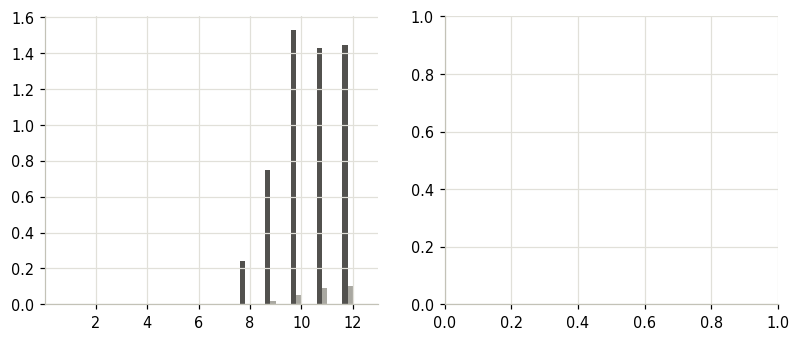

In [ ]:
# myndir
# Mynd A: mánaðarleg afhending og vatnsstaða
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.4))
ax = axs[0]
w = 0.2
ax.bar(man - 1.5 * w, cs.AUKA - hopur_ferlar["man"]["Ex"], w, color=LIT["hopur"], label="Hópur, eitt ár (V₁=1600)")
ax.bar(man - 0.5 * w, cs.AUKA - hopur_endurt["man"]["Ex"], w, color="#a9a8a1", label="Hópur, endurtekin ár")
for k, b in enumerate(BETA):
    ax.bar(man + (k + 0.5) * w, cs.AUKA - lausnir[b]["r"]["man"]["Ex"], w, color=LIT[b], label=f"Óendanlegt β={b}")
ax.set_xticks(man, MAN_STAFIR); ax.set_ylabel("Vænt skerðing 54 − E[x] (MW)"); ax.set_title("a) Skerðing eftir mánuðum")
ax.legend(fontsize=7)
ax = axs[1]
ax.fill_between(man, hopur_V[0.05], hopur_V[0.95], color=LIT["hopur"], alpha=0.12, lw=0)
ax.plot(man, hopur_V[0.5], color=LIT["hopur"], label="Hópur, eitt ár (V₁=1600)")
L = lausnir[0.99]["r"]
ax.fill_between(man, L["V_hlutf"][0.05], L["V_hlutf"][0.95], color=LIT[0.99], alpha=0.12, lw=0)
ax.plot(man, L["V_hlutf"][0.5], color=LIT[0.99], label="Óendanlegt β=0,99 (stöðugt)")
ax.axhline(cs.V_MAX, color="#52514e", lw=0.8, ls="--")
ax.set_xticks(man, MAN_STAFIR); ax.set_ylabel("Vatn í lok mánaðar (Mm³)"); ax.set_title("b) Miðgildi og 5–95% bil")
ax.legend(fontsize=7.5, loc="lower right")
fig.suptitle("Mynd A. Eitt ár með lokamarkmiði á móti endurteknum árum", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(); vista(fig, "e5_myndA_afhending_vatn.png")

# Mynd B: skerðingarmörk eftir mánuðum
fig, axs = plt.subplots(1, 3, figsize=(8.8, 3.3), sharey=True)
for c in range(3):
    ax = axs[c]
    ax.plot(man, morkin["hopur"][:, c], color=LIT["hopur"], marker="o", ms=3, label="Hópur (eitt ár)")
    for b in BETA:
        ax.plot(man, morkin[b][:, c], color=LIT[b], marker="o", ms=3, label=f"β={b}")
    ax.plot(man, np.r_[L["V_hlutf"][0.5][11], L["V_hlutf"][0.5][:11]], color=LIT[0.99], lw=1, ls=":", label="Miðgildi vatns, β=0,99")
    ax.set_xticks(man, MAN_STAFIR); ax.set_title(f"{cs.FLOKKAR[c]} innrennsli", fontsize=9.5)
axs[0].set_ylabel("Skert ef vatn í byrjun mán. < (Mm³)"); axs[2].legend(fontsize=7, loc="upper left")
fig.suptitle("Mynd B. Skerðingarmörk: hæsta vatnsstaða þar sem enn er skert", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(); vista(fig, "e5_myndB_skerdingarmork.png")

# Mynd C: jaðarvirði vatns í lok árs
fig, ax = plt.subplots(figsize=(7.4, 3.3))
ax.step(Vg, vv_hopur, where="post", color=LIT["hopur"], label="Hópur: lokarefsing M = 2M* undir V₁ = 1600")
for b in BETA:
    ax.plot(Vg, vv[b], color=LIT[b], lw=1.6, label=f"Óendanlegt β={b}: β·∂G/∂V")
ax.axhline(cs.M_JAFN, color="#d03b3b", lw=1, ls="--")
ax.text(1700, cs.M_JAFN + 0.4, "M* = 1,82", fontsize=7.5, color="#d03b3b")
ax.set_xlim(cs.V_MIN, cs.V_MAX); ax.set_ylim(0, 12)
ax.set_xlabel("Vatn í lok desember (Mm³)"); ax.set_ylabel("Jaðarvirði (MW-mán á Mm³)")
ax.set_title("Mynd C. Hvað kemur í stað lokamarkmiðsins: virði vatns í lok árs"); ax.legend(fontsize=7.5)
vista(fig, "e5_myndC_vatnsvirdi.png")

# Mynd D: samleitni gildisítrunar
fig, ax = plt.subplots(figsize=(7.0, 3.0))
for b in BETA:
    s = np.array(lausnir[b]["m"].saga)
    ax.semilogy(s[:, 0], s[:, 2], color=LIT[b], label=f"β={b}: {lausnir[b]['m'].umferdir} umferðir")
ax.set_xlabel("Umferð (12 mánuðir)"); ax.set_ylabel("span(J_k − J_k−1)"); ax.legend(fontsize=8)
ax.set_title("Mynd D. Samleitni gildisítrunar")
vista(fig, "e5_myndD_samleitni.png")

json.dump({"tafla": tafla.to_dict(orient="records"),
           "skerdingarmork": {f"{a}|{b}": v for (a, b), v in morktafla.to_dict().items()},
           "vatnsvirdi": vvtafla.to_dict(), "jafngilt_lokamarkmid": {str(b): v for b, v in jafngilt.items()},
           "prof2024": ar24.to_dict(), "lam": {str(b): [L["lam"], L["stada"]] for b, L in lausnir.items()},
           "Ex": {str(b): np.round(L["r"]["man"]["Ex"], 2).tolist() for b, L in lausnir.items()},
           "Ex_hopur": np.round(hopur_ferlar["man"]["Ex"], 2).tolist(), "Ex_hopur_endurt": np.round(hopur_endurt["man"]["Ex"], 2).tolist()},
          open(os.path.join(UT, "nidurstodur_e5.json"), "w"), ensure_ascii=False, indent=1, default=str)
print("Lokið")

#Niðurstöður

Þegar árin eru látin endurtaka sig, þannig að desember leiðir aftur í janúar og vatnsstaðan flyst yfir áramót, þarf
hvorki fasta upphafsstöðu né lokamarkmið. Helstu niðurstöður eru:

- **Engin skerðing til lengri tíma.** Í stöðugu ástandi afhendir óendanlega stefnan öll 54 MW í hverjum mánuði
  (473,0 GWh á ári) með 100% áreiðanleika forgangsorku. Áreiðanleikaskilyrðið bindur ekki (λ* = 0) fyrir neitt β.
  Til samanburðar skerðir stefna hópsins 3,9 GWh á ári þegar byrjað er í 1600 Mm³.
- **Lónið ræður upphafsstöðunni sjálft.** Til lengdar er vatnsstaðan í janúar um 1805/1865/2108 Mm³ (5/50/95%), sem
  er hærra en sú upphafsstaða sem hópurinn gefur sér.
- **Lokamarkmið hópsins er strangara en þörf er á.** Í stað lokamarkmiðsins kemur jaðarvirði vatns í lok árs. Vatn í
  lok árs er aðeins meira virði en að afhenda það strax undir um 1080–1100 Mm³. Ofan við um 1250 Mm³ er það nánast
  einskis virði, því lónið fyllist og flæðir yfir næsta sumar. Hópurinn refsar hins vegar fyrir hvern Mm³ undir 1600.
- **Munurinn liggur á haustin.** Í janúar–júlí eru stefnurnar eins, því þar ræður verndun forgangsorkunnar. Í ágúst–
  desember skerðir stefna hópsins ef vatnið er undir um 1700–1980 Mm³, en óendanlega stefnan aðeins undir um
  1150–1480 Mm³.
- **β skiptir litlu máli.** Hærra β hækkar haustmörkin og vatnsvirðið lítillega, en hvatinn til að geyma vatn ræðst
  af skortsáhættu innan ársins og yfirfalli, ekki af fjarlægri framtíð. Hærra β gerir reikninginn hins vegar mun
  þyngri: 26, 111 og 923 umferðir fyrir β = 0,95, 0,99 og 0,999.
- **Lág staða í janúar.** Ef árið byrjar lágt skerðir óendanlega stefnan minna en stefna hópsins. Frá 1000 Mm³ eru það
  124 GWh á móti 178 GWh, því hún þarf ekki að fylla lónið upp í 1600 fyrir áramót.

**Ályktanir:** Árlegt lokamarkmið um að enda árið í upphafsstöðu leiðir til óþarfa skerðinga á haustin. Lónið fyllist
að jafnaði aftur næsta sumar, svo það vatn sem geymt er umfram um 1250 Mm³ fer oftast í yfirfall. Raunhæfara væri
að miða lokamarkmiðið við um 1100 Mm³, eða að meta vatnið í lok árs með framtíðargildi líkt og hér er gert. Þessar
niðurstöður byggja þó á innrennslislíkani hópsins, sem ýkir sveiflur milli ára. Þær taka heldur ekki tillit til
annarra notenda raforkukerfisins eða flutningstakmarkana.

In [241]:
from pathlib import Path
import shutil

uppspretta = Path("/content/curtail_sdp.py")
markskra = Path(
    "/content/drive/MyDrive/When_to_Curtail/einstaklingsverkefni_5.py"
)

shutil.copy2(uppspretta, markskra)

print("Einstaklingsverkefni 5 vistað:", markskra.exists())
print("Stærð:", markskra.stat().st_size, "bæti")

Einstaklingsverkefni 5 vistað: True
Stærð: 25129 bæti
